# FarmTech Solutions — Visão computacional: vaca × trator

**FIAP · Inteligência Artificial · Fase 6 · PBL**

Este notebook reúne as duas entregas obrigatórias da fase:

| Seção | Conteúdo |
|---|---|
| **Entrega 1** | Dataset próprio (40 vacas + 40 tratores), rotulação no Make Sense, treino, validação e teste de um **YOLOv5 customizado** com **30 e 60 épocas** e comparação entre as simulações |
| **Entrega 2** | Comparação crítica entre **YOLO customizado**, **YOLO tradicional (COCO)** e **CNN treinada do zero** em facilidade de uso, precisão, tempo de treino e tempo de inferência |

**Como executar:** no Colab, ative a GPU (*Ambiente de execução › Alterar o tipo de ambiente › GPU*) e use *Executar tudo*. O dataset deve estar em `MyDrive/fiap_fase6/dataset` (veja o README do repositório). Fora do Colab o notebook usa a pasta `dataset/` local.

Convenção: cada célula de código é precedida por uma célula de texto que explica o que ela faz.

# Entrega 1 — Detector YOLOv5 customizado: vaca × trator

A **FarmTech Solutions** passou a oferecer visão computacional para o agronegócio. Esta entrega mostra, de ponta a ponta, como treinar um detector de objetos **YOLOv5** para reconhecer duas classes de interesse no campo:

| id | classe | imagens | treino | validação | teste |
|---|---|---|---|---|---|
| 0 | `vaca` | 40 | 32 | 4 | 4 |
| 1 | `trator` | 40 | 32 | 4 | 4 |

**Como o dataset foi rotulado.** As imagens vêm do Wikimedia Commons (créditos em `dataset/CREDITS.md`). Para agilizar o trabalho, as caixas foram **pré-geradas automaticamente**: YOLO11 para `vaca`, que é uma classe do COCO, e YOLO-World, um detector de vocabulário aberto, para `trator`. Em seguida, todas foram **revisadas e ajustadas manualmente no Make Sense** e exportadas no formato YOLO (`classe x_centro y_centro largura altura`, normalizados entre 0 e 1). O resultado está organizado em `dataset/images/{train,val,test}` e `dataset/labels/{train,val,test}`.

Roteiro:
1. Configuração do ambiente (Colab + Google Drive ou execução local).
2. Treinamento de duas simulações com épocas bem diferentes: **30** e **60**.
3. Curvas de erro (*losses*) e de acurácia por época.
4. Validação e teste de cada modelo.
5. Comparação de acurácia, erro e desempenho.
6. Detecção nas imagens de teste (`yolov5/runs/detect/expX`) e persistência dos resultados.
7. Conclusões, pontos fortes e limitações.

## 1. Configuração do ambiente

### 1.1 Bibliotecas e constantes de ambiente
Importamos aqui as **bibliotecas comuns** do notebook (a Entrega 2 importa as suas próprias na seção 8) e definimos em um só lugar os caminhos que mudam entre o **Google Colab** (Drive montado em `/content/drive`) e a execução local. Para detectar o Colab, verificamos se o módulo `google.colab` está carregado.

In [1]:
import contextlib
import io
import json
import logging
import os
import re
import shutil
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Markdown, display

IN_COLAB = "google.colab" in sys.modules
DRIVE_MOUNT = Path("/content/drive")
DRIVE_DATA_ROOT = DRIVE_MOUNT / "MyDrive" / "fiap_fase6" / "dataset"
COLAB_YOLO_DIR = Path("/content/yolov5")
YOLO_REPO = "https://github.com/ultralytics/yolov5"
YOLO_COMMIT = "f9578796b8a64889aa9e66dc06914d19f40d338e"
ULTRALYTICS_PIN = "ultralytics==8.4.175"
DATASET_FOLDER = "dataset"
YOLO_FOLDER = "yolov5"
CLASS_FILE = "classes.txt"
SPLITS = ("train", "val", "test")
IMAGE_SUFFIX = ".jpg"

print(f"Colab: {IN_COLAB} | PyTorch {torch.__version__} | CUDA disponível: {torch.cuda.is_available()}")

Colab: False | PyTorch 2.14.1+cu126 | CUDA disponível: True


### 1.2 Conexão com o Google Drive e localização dos dados
No Colab, montamos o Google Drive e apontamos `DATA_ROOT` para `MyDrive/fiap_fase6/dataset`. Se o dataset não estiver lá, a célula para com uma mensagem explicando onde colocá-lo. Localmente, subimos a partir da pasta atual até encontrar o diretório `dataset/` do projeto. `PROJECT_DIR` é a pasta que contém o dataset: no Colab é a pasta do projeto no Drive, onde também gravamos figuras e resultados. O YOLOv5 fica em `/content/yolov5` (Colab) ou em `yolov5/` na raiz do projeto.

In [2]:
def find_project_root(start: Path) -> Path:
    for folder in (start, *start.parents):
        if (folder / DATASET_FOLDER).is_dir():
            return folder
    raise FileNotFoundError(f"Pasta {DATASET_FOLDER}/ não encontrada acima de {start}")


def resolve_paths() -> tuple[Path, Path]:
    if IN_COLAB:
        from google.colab import drive
        drive.mount(str(DRIVE_MOUNT))
        if not (DRIVE_DATA_ROOT / CLASS_FILE).exists():
            raise FileNotFoundError(
                f"Dataset não encontrado em {DRIVE_DATA_ROOT}. Copie a pasta dataset/ do projeto "
                f"(com images/, labels/ e {CLASS_FILE}) para MyDrive/fiap_fase6/ no Google Drive e execute de novo."
            )
        return DRIVE_DATA_ROOT, COLAB_YOLO_DIR
    root = find_project_root(Path.cwd().resolve())
    return root / DATASET_FOLDER, root / YOLO_FOLDER


DATA_ROOT, YOLO_DIR = resolve_paths()
PROJECT_DIR = DATA_ROOT.parent
RUNS_DIR = YOLO_DIR / "runs"
print(f"PROJECT_DIR = {PROJECT_DIR}\nDATA_ROOT   = {DATA_ROOT}\nYOLO_DIR    = {YOLO_DIR}")

PROJECT_DIR = C:\Users\leelt\fiap-fase6
DATA_ROOT   = C:\Users\leelt\fiap-fase6\dataset
YOLO_DIR    = C:\Users\leelt\fiap-fase6\yolov5


### 1.3 Repositório YOLOv5 (versão fixa)
Clonamos o repositório oficial da Ultralytics somente se ele ainda não existir e fixamos o *commit* `f9578796`, a versão usada para gerar os resultados, para que uma atualização futura do YOLOv5 não mude o comportamento do notebook. No Colab, primeiro fixamos o pacote `ultralytics` na versão 8.4.175, porque esse *commit* do YOLOv5 importa funções internas dele. Depois instalamos o `requirements.txt` em modo silencioso e **sem** `--upgrade`: o `pip` só instala o que estiver faltando e preserva as versões do Colab (numpy, torch), sem exigir reinício do ambiente. Por fim, o treino usa a GPU `0` quando disponível.

In [3]:
def ensure_yolov5(yolo_dir: Path) -> None:
    if not yolo_dir.exists():
        subprocess.run(["git", "clone", "--quiet", YOLO_REPO, str(yolo_dir)], check=True)
        subprocess.run(["git", "-C", str(yolo_dir), "checkout", "--quiet", YOLO_COMMIT], check=True)
    if IN_COLAB:
        pip = [sys.executable, "-m", "pip", "install", "-q"]
        subprocess.run([*pip, ULTRALYTICS_PIN], check=True)
        subprocess.run([*pip, "-r", str(yolo_dir / "requirements.txt")], check=True)


ensure_yolov5(YOLO_DIR)
DEVICE = "0" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else DEVICE}")

Dispositivo: NVIDIA GeForce RTX 4070 Laptop GPU


### 1.4 Inventário do dataset
Antes de treinar, conferimos se cada split tem a quantidade esperada de imagens por classe e se toda imagem tem seu arquivo de rótulo `.txt`. Os nomes das classes vêm de `classes.txt`, exportado pelo Make Sense.

Esta célula também define duas funções usadas no resto do notebook:
- `class_from_name`: lê a classe real do nome do arquivo (`vaca_001.jpg` → `vaca`);
- `fmt_num`: formata números com vírgula decimal nos textos em português.

In [4]:
CLASS_NAMES = [line.strip() for line in (DATA_ROOT / CLASS_FILE).read_text(encoding="utf-8").splitlines() if line.strip()]


def class_from_name(path: Path) -> str:
    return Path(path).stem.rsplit("_", 1)[0]


def fmt_num(value: float, digits: int = 3, signed: bool = False) -> str:
    return f"{value:{'+' if signed else ''}.{digits}f}".replace(".", ",")


def count_split(split: str) -> dict[str, object]:
    images = list((DATA_ROOT / "images" / split).glob(f"*{IMAGE_SUFFIX}"))
    labels = {path.stem for path in (DATA_ROOT / "labels" / split).glob("*.txt")}
    per_class = {name: sum(class_from_name(path) == name for path in images) for name in CLASS_NAMES}
    return {"split": split, **per_class, "imagens": len(images), "com rótulo": sum(path.stem in labels for path in images)}


INVENTORY = pd.DataFrame(map(count_split, SPLITS)).set_index("split")
print(f"Classes: {CLASS_NAMES}")
INVENTORY

Classes: ['vaca', 'trator']


,vaca,trator,imagens,com rótulo
split,,,,
train,32,32,64,64
val,4,4,8,8
test,4,4,8,8


### 1.5 Arquivo de configuração do dataset (YAML)
O YOLOv5 lê um YAML com a raiz do dataset, os caminhos de treino, validação e teste, o número de classes (`nc`) e seus nomes. Gravamos esse arquivo em `yolov5/runs/e1/`, e assim o mesmo código funciona no Colab e localmente.

In [5]:
WORK_DIR = RUNS_DIR / "e1"
DATA_YAML = WORK_DIR / "farmtech.yaml"


def write_data_yaml(path: Path) -> Path:
    path.parent.mkdir(parents=True, exist_ok=True)
    config = {
        "path": DATA_ROOT.as_posix(),
        **{split: f"images/{split}" for split in SPLITS},
        "nc": len(CLASS_NAMES),
        "names": CLASS_NAMES,
    }
    path.write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding="utf-8")
    return path


print(write_data_yaml(DATA_YAML).read_text(encoding="utf-8"))

path: C:/Users/leelt/fiap-fase6/dataset
train: images/train
val: images/val
test: images/test
nc: 2
names:
- vaca
- trator



## 2. Treinamento

### 2.1 Hiperparâmetros e executor de scripts
Partimos do **`yolov5s.pt`**, pré-treinado no COCO (*transfer learning*). Com apenas 32 imagens por classe, é o reaproveitamento dos filtros já aprendidos que torna o treino viável. Fixamos imagem de 640 px, *batch* 16 e **semente 42**, para que as duas simulações difiram apenas no número de épocas.

A função `run_yolo` chama os scripts do YOLOv5 com o mesmo Python do notebook (`subprocess`). Ela mede o tempo de parede e mostra as últimas linhas do log, sem os códigos de cor ANSI e sem as linhas de barra de progresso. Registramos dois tempos por treino em `TRAIN_TIMES`:
- o **total**, que inclui download de pesos, cache do dataset e validação final;
- o do **laço de épocas**, informado pelo próprio YOLOv5 em horas com 3 casas (resolução de 3,6 s). É a medida justa para comparar 30 × 60 épocas.

A pasta de cada treino é apagada antes de começar, porque o YOLOv5 acrescenta linhas a um `results.csv` já existente.

In [6]:
WEIGHTS = "yolov5s.pt"
IMG_SIZE = 640
BATCH = 16
SEED = 42
WORKERS = 2
EPOCH_PLAN = {"e30": 30, "e60": 60}
LOG_TAIL = 12
CHILD_ENV = {**os.environ, "PYTHONIOENCODING": "utf-8"}
ANSI_PATTERN = re.compile(r"\x1b\[[0-9;]*[A-Za-z]")
PROGRESS_PATTERN = re.compile(r"\d+%\s*[━─█|]")
EPOCH_LOOP_PATTERN = re.compile(r"epochs completed in ([\d.]+) hours")
SECONDS_PER_HOUR = 3600
TRAIN_TIMES: dict[str, dict[str, float]] = {}


def run_yolo(script: str, *args: object) -> tuple[str, float]:
    start = time.perf_counter()
    result = subprocess.run(
        [sys.executable, script, *map(str, args)],
        cwd=YOLO_DIR, env=CHILD_ENV, text=True, encoding="utf-8", errors="replace",
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    elapsed = time.perf_counter() - start
    log = ANSI_PATTERN.sub("", result.stdout)
    readable = [line for line in log.splitlines() if not PROGRESS_PATTERN.search(line)]
    print("\n".join(readable[-LOG_TAIL:]))
    result.check_returncode()
    return log, elapsed


def train(name: str) -> None:
    shutil.rmtree(RUNS_DIR / "train" / name, ignore_errors=True)
    log, seconds = run_yolo(
        "train.py", "--img", IMG_SIZE, "--batch", BATCH, "--epochs", EPOCH_PLAN[name],
        "--data", DATA_YAML, "--weights", WEIGHTS, "--seed", SEED, "--workers", WORKERS,
        "--device", DEVICE, "--project", RUNS_DIR / "train", "--name", name, "--exist-ok",
    )
    loop_seconds = float(EPOCH_LOOP_PATTERN.findall(log)[-1]) * SECONDS_PER_HOUR
    TRAIN_TIMES[name] = {"epochs": EPOCH_PLAN[name], "total_s": seconds, "epoch_loop_s": loop_seconds}
    print(f"\n{name}: total {seconds:.1f} s | laço de épocas {loop_seconds:.1f} s")

### 2.2 Simulação 1 — 30 épocas
O primeiro treino, mais curto. Os resultados ficam em `yolov5/runs/train/e30`: pesos `best.pt` e `last.pt`, `results.csv` e gráficos.

In [7]:
train("e30")

30 epochs completed in 0.010 hours.
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30\weights\last.pt, 14.4MB
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30\weights\best.pt, 14.4MB

Validating C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30\weights\best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients

                   all          8         20      0.889      0.776      0.809      0.473
                  vaca          8         16      0.778      0.562      0.624      0.336
                trator          8          4          1       0.99      0.995      0.609
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\train\e30

e30: total 73.7 s | laço de épocas 36.0 s


### 2.3 Simulação 2 — 60 épocas
A mesma configuração com o dobro de épocas, para medir se o treino mais longo compensa em acurácia. Os resultados ficam em `yolov5/runs/train/e60`.

In [8]:
train("e60")

60 epochs completed in 0.019 hours.
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\last.pt, 14.4MB
Optimizer stripped from C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\best.pt, 14.4MB

Validating C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60\weights\best.pt...
Fusing layers... 
Model summary: 68 layers, 7,015,519 parameters, 0 gradients

                   all          8         20      0.833      0.714      0.795      0.564
                  vaca          8         16      0.695      0.428      0.596      0.362
                trator          8          4      0.972          1      0.995      0.767
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\train\e60

e60: total 102.2 s | laço de épocas 68.4 s


## 3. Curvas de treinamento

### 3.1 Leitura do histórico
Cada treino grava `results.csv` com uma linha por época. Ali estão as três *losses* de treino e de validação e as métricas de validação:
- **box**: erro de localização da caixa;
- **obj**: erro na pergunta "há um objeto aqui?";
- **cls**: erro de classificação.

Os nomes das colunas vêm com espaços, que removemos. A função `render` exibe as figuras de forma explícita, porque o YOLOv5 troca o *backend* do matplotlib para `Agg` ao ser importado, e com isso `plt.show()` não mostraria nada.

In [9]:
LOSS_COLUMNS = ["train/box_loss", "train/obj_loss", "train/cls_loss", "val/box_loss", "val/obj_loss", "val/cls_loss"]
METRIC_COLUMNS = ["metrics/precision", "metrics/recall", "metrics/mAP_0.5", "metrics/mAP_0.5:0.95"]
PANEL_TITLES = {
    "metrics/precision": "precisão (P)", "metrics/recall": "revocação (R)",
    "metrics/mAP_0.5": "mAP50", "metrics/mAP_0.5:0.95": "mAP50-95",
}
RUN_COLORS = {"e30": "#2a78d6", "e60": "#eb6834"}
PANEL_SIZE = (4.6, 3.2)
PANEL_COLUMNS = 3
LINE_WIDTH = 2
GRID_ALPHA = 0.3


def render(fig: plt.Figure) -> None:
    display(fig)
    plt.close(fig)


def style_axis(ax: plt.Axes, title: str) -> None:
    ax.set_title(title)
    ax.grid(alpha=GRID_ALPHA)
    ax.spines[["top", "right"]].set_visible(False)


def load_history(name: str) -> pd.DataFrame:
    history = pd.read_csv(RUNS_DIR / "train" / name / "results.csv")
    history.columns = history.columns.str.strip()
    return history


HISTORY = {name: load_history(name) for name in EPOCH_PLAN}
HISTORY["e60"].tail()

,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,metrics/recall,metrics/mAP_0.5,metrics/mAP_0.5:0.95,val/box_loss,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
55,55,0.036643,0.025665,0.001300,0.83352,0.71397,0.79385,0.56317,0.052788,0.016701,0.001753,0.001090,0.001090,0.001090
56,56,0.035868,0.019312,0.001620,0.83557,0.71580,0.78235,0.53724,0.052598,0.016693,0.001742,0.000925,0.000925,0.000925
57,57,0.035956,0.023219,0.001459,0.83589,0.71576,0.79576,0.51982,0.051929,0.016680,0.001699,0.000760,0.000760,0.000760
58,58,0.034991,0.023040,0.001491,0.83446,0.71302,0.80367,0.54628,0.052500,0.016632,0.001678,0.000595,0.000595,0.000595
59,59,0.029303,0.018334,0.001299,0.83672,0.71636,0.80159,0.54852,0.053222,0.016565,0.001683,0.000430,0.000430,0.000430


### 3.2 Erro por época (30 × 60)
Sobrepomos as curvas das duas simulações em painéis com o mesmo eixo de épocas. Como a semente é a mesma, as duas curvas tendem a coincidir nas primeiras épocas. O que interessa é o que acontece depois da época 30.

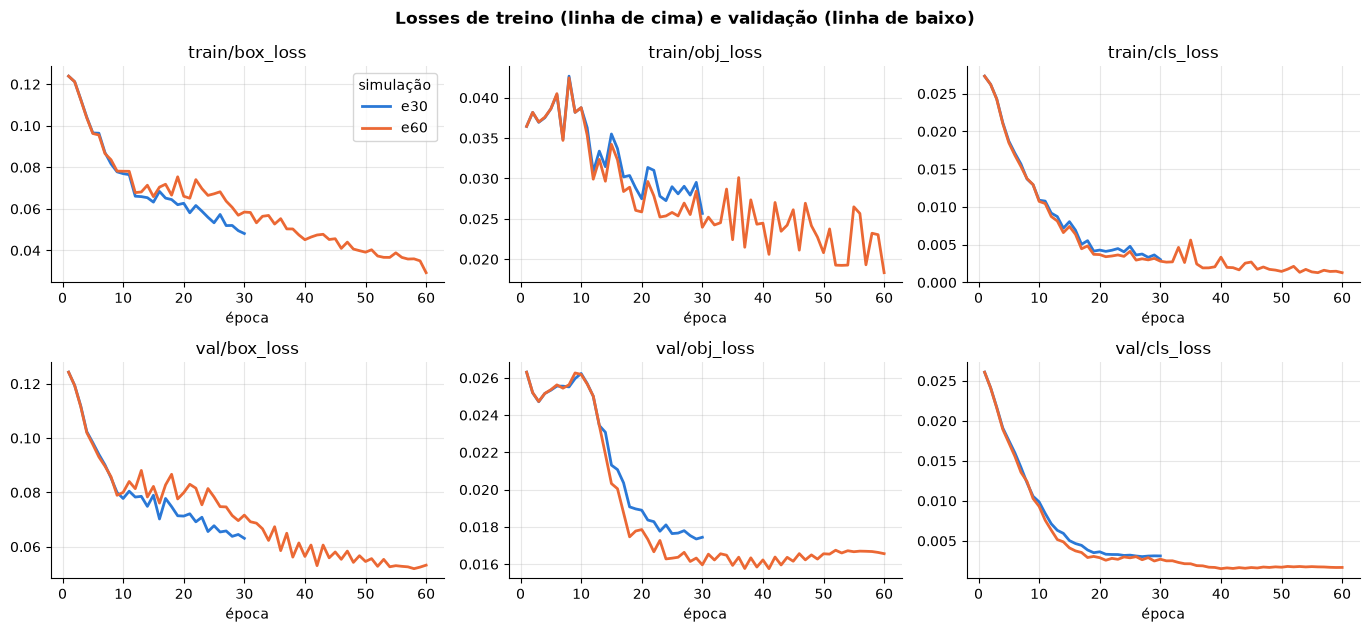

In [10]:
def plot_history(columns: list[str], title: str) -> None:
    rows = -(-len(columns) // PANEL_COLUMNS)
    fig, axes = plt.subplots(rows, PANEL_COLUMNS, figsize=(PANEL_SIZE[0] * PANEL_COLUMNS, PANEL_SIZE[1] * rows), squeeze=False)
    for ax in axes.flat[len(columns):]:
        ax.axis("off")
    for ax, column in zip(axes.flat, columns):
        for name, history in HISTORY.items():
            ax.plot(history["epoch"] + 1, history[column], color=RUN_COLORS[name], linewidth=LINE_WIDTH, label=name)
        style_axis(ax, PANEL_TITLES.get(column, column))
        ax.set_xlabel("época")
    axes.flat[0].legend(title="simulação")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    render(fig)


plot_history(LOSS_COLUMNS, "Losses de treino (linha de cima) e validação (linha de baixo)")

### 3.3 Acurácia por época (30 × 60)
Quatro métricas, medidas no conjunto de validação ao fim de cada época:
- **precisão (P)**: fração das detecções que estão corretas;
- **revocação/recall (R)**: fração dos objetos reais que foram encontrados;
- **mAP50**: acerto exigindo sobreposição (IoU) de pelo menos 0,5;
- **mAP50-95**: média com IoU de 0,5 a 0,95, mais exigente quanto ao ajuste da caixa.

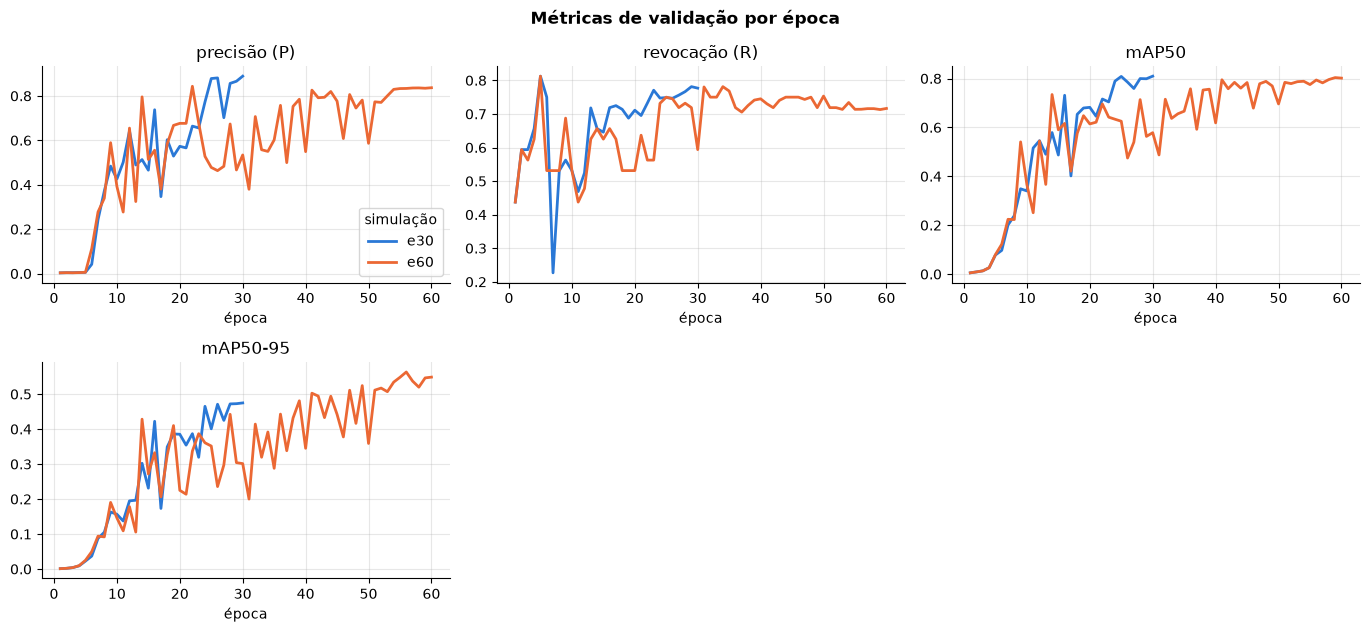

In [11]:
plot_history(METRIC_COLUMNS, "Métricas de validação por época")

## 4. Validação e teste

### 4.1 Avaliação com `val.py`
Avaliamos o melhor peso (`best.pt`) de cada simulação em dois splits:
- **validação**;
- **teste** (`task="test"`): imagens que não foram usadas no treino nem na escolha do `best.pt`.

Importamos o `val.py` do YOLOv5 e chamamos `val.run`, que devolve as métricas diretamente. O *logger* e as barras de progresso do YOLOv5 ficam silenciados durante a avaliação (`quiet_yolo`), e só imprimimos um resumo por avaliação. Usamos *batch* 1 para que o tempo de inferência informado seja **por imagem**. Os relatórios completos ficam em `yolov5/runs/val/<modelo>_<split>`.

In [12]:
EVAL_TASKS = ("val", "test")
EVAL_BATCH = 1
EVAL_WORKERS = 0
PRECISION, RECALL = "precisão (P)", "revocação (R)"
HEADLINE_METRICS = [PRECISION, RECALL, "mAP50", "mAP50-95"]

if str(YOLO_DIR) not in sys.path:
    sys.path.insert(0, str(YOLO_DIR))
import val as yolo_val
from utils.general import LOGGER as YOLO_LOGGER


@contextlib.contextmanager
def quiet_yolo():
    level = YOLO_LOGGER.level
    YOLO_LOGGER.setLevel(logging.ERROR)
    try:
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            yield
    finally:
        YOLO_LOGGER.setLevel(level)


def best_weights(name: str) -> Path:
    return RUNS_DIR / "train" / name / "weights" / "best.pt"


def evaluate(name: str, task: str) -> dict[str, object]:
    with quiet_yolo():
        (precision, recall, map50, map50_95, *_), per_class, speed = yolo_val.run(
            data=DATA_YAML, weights=best_weights(name), batch_size=EVAL_BATCH, imgsz=IMG_SIZE, task=task,
            device=DEVICE, workers=EVAL_WORKERS, project=RUNS_DIR / "val", name=f"{name}_{task}", exist_ok=True,
        )
    print(f"{name} | {task}: P={fmt_num(precision)} R={fmt_num(recall)} mAP50={fmt_num(map50)} "
          f"mAP50-95={fmt_num(map50_95)} -> runs/val/{name}_{task}")
    return {
        "modelo": name, "split": task, PRECISION: precision, RECALL: recall,
        "mAP50": map50, "mAP50-95": map50_95,
        **{f"mAP50-95 {cls}": per_class[index] for index, cls in enumerate(CLASS_NAMES)},
        "inferência (ms/img)": speed[1],
    }


EVALUATION = pd.DataFrame([evaluate(name, task) for name in EPOCH_PLAN for task in EVAL_TASKS])
EVALUATION.round(3)

e30 | val: P=0,925 R=0,781 mAP50=0,818 mAP50-95=0,491 -> runs/val/e30_val


e30 | test: P=0,748 R=0,764 mAP50=0,813 mAP50-95=0,529 -> runs/val/e30_test


e60 | val: P=0,833 R=0,719 mAP50=0,798 mAP50-95=0,577 -> runs/val/e60_val


e60 | test: P=0,980 R=0,764 mAP50=0,804 mAP50-95=0,534 -> runs/val/e60_test


,modelo,split,precisão (P),revocação (R),mAP50,mAP50-95,mAP50-95 vaca,mAP50-95 trator,inferência (ms/img)
0,e30,val,0.925,0.781,0.818,0.491,0.374,0.609,12.937
1,e30,test,0.748,0.764,0.813,0.529,0.436,0.621,12.936
2,e60,val,0.833,0.719,0.798,0.577,0.387,0.766,10.674
3,e60,test,0.980,0.764,0.804,0.534,0.412,0.656,10.908


## 5. Comparação entre as simulações

### 5.1 Tabela consolidada
Juntamos, para cada modelo:
- **desempenho**: tempo total de treino, tempo do laço de épocas, segundos por época e tempo de inferência por imagem no `val.py`;
- **erro**: *losses* finais de treino e de validação, da última época do `results.csv`;
- **acurácia** no teste.

In [13]:
def training_summary(name: str) -> dict[str, object]:
    last = HISTORY[name].iloc[-1]
    return {
        "modelo": name, "épocas": EPOCH_PLAN[name],
        "treino total (s)": TRAIN_TIMES[name]["total_s"], "laço de épocas (s)": TRAIN_TIMES[name]["epoch_loop_s"],
        "s/época": TRAIN_TIMES[name]["epoch_loop_s"] / EPOCH_PLAN[name],
        **{column: last[column] for column in LOSS_COLUMNS},
    }


TRAINING = pd.DataFrame(map(training_summary, EPOCH_PLAN)).set_index("modelo")
TEST_METRICS = EVALUATION.query("split == 'test'").drop(columns="split").set_index("modelo")
COMPARISON = TRAINING.join(TEST_METRICS.add_prefix("teste "))
COMPARISON.T.round(4)

modelo,e30,e60
épocas,30.0000,60.0000
treino total (s),73.6732,102.1826
laço de épocas (s),36.0000,68.4000
s/época,1.2000,1.1400
train/box_loss,0.0481,0.0293
train/obj_loss,0.0257,0.0183
train/cls_loss,0.0030,0.0013
val/box_loss,0.0631,0.0532
val/obj_loss,0.0174,0.0166
val/cls_loss,0.0031,0.0017


### 5.2 Acurácia lado a lado
Barras agrupadas com as quatro métricas principais, em validação e teste, para os dois modelos. Todas estão na mesma escala, de 0 a 1.

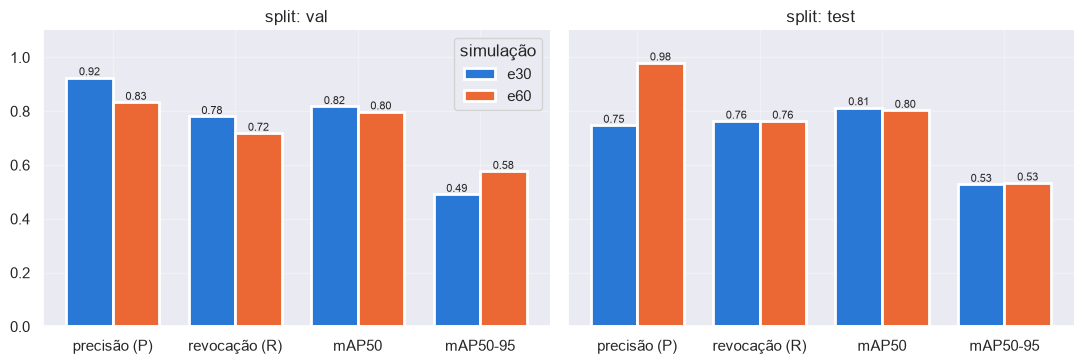

In [14]:
BAR_WIDTH = 0.38
ACCURACY_FIGSIZE = (11.0, 3.8)
SCORE_AXIS_TOP = 1.1
BAR_LABEL_SIZE = 8


def plot_accuracy() -> None:
    fig, axes = plt.subplots(1, len(EVAL_TASKS), figsize=ACCURACY_FIGSIZE, sharey=True)
    positions = range(len(HEADLINE_METRICS))
    for ax, task in zip(axes, EVAL_TASKS):
        scores = EVALUATION.query("split == @task").set_index("modelo")[HEADLINE_METRICS]
        for offset, name in enumerate(EPOCH_PLAN):
            bars = ax.bar([p + offset * BAR_WIDTH for p in positions], scores.loc[name], BAR_WIDTH,
                          color=RUN_COLORS[name], edgecolor="white", linewidth=LINE_WIDTH, label=name)
            ax.bar_label(bars, fmt="%.2f", fontsize=BAR_LABEL_SIZE)
        ax.set_xticks([p + BAR_WIDTH / 2 for p in positions], HEADLINE_METRICS)
        ax.set_ylim(0, SCORE_AXIS_TOP)
        style_axis(ax, f"split: {task}")
    axes[0].legend(title="simulação")
    fig.tight_layout()
    render(fig)


plot_accuracy()

### 5.3 Escolha do melhor modelo
O critério é o **mAP50-95 na validação**: é a métrica mais exigente, medida em dados que não participaram do ajuste dos pesos. Em caso de empate, decide o teste e, por fim, o modelo mais barato de treinar.

In [15]:
SCORES = EVALUATION.pivot(index="modelo", columns="split", values="mAP50-95").join(TRAINING["épocas"])
BEST = SCORES.sort_values(["val", "test", "épocas"], ascending=[False, False, True]).index[0]
print(f"Melhor modelo: {BEST}")
SCORES.round(4)

Melhor modelo: e60


,test,val,épocas
modelo,,,
e30,0.5288,0.4915,30
e60,0.5337,0.5769,60


## 6. Detecção nas imagens de teste

### 6.1 `detect.py` com os dois modelos
Rodamos o `detect.py` sobre `dataset/images/test` com cada `best.pt`, com confiança mínima de 0,25. Cada execução cria uma nova pasta `yolov5/runs/detect/expX`, que identificamos comparando as pastas antes e depois. Também guardamos os rótulos previstos (`--save-txt --save-conf`) e o tempo de inferência por imagem relatado pelo próprio script.

In [16]:
DETECT_DIR = RUNS_DIR / "detect"
CONF_THRES = 0.25
SPEED_PATTERN = re.compile(r"([\d.]+)ms inference")
TEST_IMAGES = DATA_ROOT / "images" / "test"


def detect(name: str) -> dict[str, object]:
    before = set(DETECT_DIR.glob("exp*"))
    log, _ = run_yolo(
        "detect.py", "--weights", best_weights(name), "--source", TEST_IMAGES, "--img", IMG_SIZE,
        "--conf-thres", CONF_THRES, "--device", DEVICE, "--project", DETECT_DIR, "--save-txt", "--save-conf",
    )
    (folder,) = set(DETECT_DIR.glob("exp*")) - before
    return {"modelo": name, "pasta": folder, "detect.py inferência (ms/img)": float(SPEED_PATTERN.findall(log)[-1])}


DETECTIONS = pd.DataFrame(map(detect, EPOCH_PLAN)).set_index("modelo")
for name, folder in DETECTIONS["pasta"].items():
    print(f"{name}: resultados salvos em {folder}")
DETECTIONS

Model summary: 68 layers, 7,015,519 parameters, 0 gradients
image 1/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_037.jpg: 480x640 1 trator, 15.8ms
image 2/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_038.jpg: 448x640 1 trator, 16.3ms
image 3/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_039.jpg: 448x640 1 trator, 11.5ms
image 4/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_040.jpg: 480x640 1 trator, 12.4ms
image 5/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_037.jpg: 448x640 1 vaca, 12.3ms
image 6/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_038.jpg: 512x640 1 vaca, 14.7ms
image 7/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_039.jpg: 640x448 2 vacas, 16.1ms
image 8/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_040.jpg: 448x640 3 vacas, 11.7ms
Speed: 0.5ms pre-process, 13.9ms inference, 10.2ms NMS per image at shape (1, 3, 640, 640)
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp
8 labels saved to C:\

Model summary: 68 layers, 7,015,519 parameters, 0 gradients
image 1/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_037.jpg: 480x640 1 trator, 15.9ms
image 2/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_038.jpg: 448x640 1 trator, 16.5ms
image 3/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_039.jpg: 448x640 1 trator, 8.8ms
image 4/8 C:\Users\leelt\fiap-fase6\dataset\images\test\trator_040.jpg: 480x640 1 trator, 11.9ms
image 5/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_037.jpg: 448x640 1 vaca, 12.7ms
image 6/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_038.jpg: 512x640 1 vaca, 15.7ms
image 7/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_039.jpg: 640x448 2 vacas, 16.9ms
image 8/8 C:\Users\leelt\fiap-fase6\dataset\images\test\vaca_040.jpg: 448x640 4 vacas, 12.4ms
Speed: 0.5ms pre-process, 13.9ms inference, 10.4ms NMS per image at shape (1, 3, 640, 640)
Results saved to C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp2
8 labels saved to C:\

,pasta,detect.py inferência (ms/img)
modelo,,
e30,C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp,13.9
e60,C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp2,13.9


### 6.2 Acertos por imagem
Lemos os `.txt` gerados pelo `detect.py` e comparamos a classe de maior confiança com a classe real, obtida do nome do arquivo por `class_from_name`. É a visão que um cliente entende de imediato: *o modelo acertou o que havia na foto?*

In [17]:
def read_predictions(label_file: Path) -> list[tuple[str, float]]:
    if not label_file.exists():
        return []
    rows = [line.split() for line in label_file.read_text().splitlines() if line.strip()]
    return sorted(((CLASS_NAMES[int(row[0])], float(row[-1])) for row in rows), key=lambda item: -item[1])


def per_image_report(name: str) -> pd.DataFrame:
    folder = DETECTIONS.loc[name, "pasta"]
    rows = []
    for image in sorted(folder.glob(f"*{IMAGE_SUFFIX}")):
        predictions = read_predictions(folder / "labels" / f"{image.stem}.txt")
        truth = class_from_name(image)
        top = predictions[0][0] if predictions else "nenhuma"
        rows.append({
            "imagem": image.name, "classe real": truth, "classe prevista": top, "acerto": top == truth,
            "caixas": len(predictions), "maior confiança": predictions[0][1] if predictions else 0.0,
            "detecções": ", ".join(f"{cls} {conf:.2f}" for cls, conf in predictions) or "—",
        })
    return pd.DataFrame(rows).set_index("imagem")


REPORTS = {name: per_image_report(name) for name in EPOCH_PLAN}
HIT_RATE = pd.Series({name: report["acerto"].mean() for name, report in REPORTS.items()}, name="acerto por imagem")
print(HIT_RATE.map("{:.0%}".format).to_string())
REPORTS[BEST]

e30    100%
e60    100%


,classe real,classe prevista,acerto,caixas,maior confiança,detecções
imagem,,,,,,
trator_037.jpg,trator,trator,True,1,0.492310,trator 0.49
trator_038.jpg,trator,trator,True,1,0.649914,trator 0.65
trator_039.jpg,trator,trator,True,1,0.711940,trator 0.71
trator_040.jpg,trator,trator,True,1,0.633061,trator 0.63
vaca_037.jpg,vaca,vaca,True,1,0.642580,vaca 0.64
vaca_038.jpg,vaca,vaca,True,1,0.836501,vaca 0.84
vaca_039.jpg,vaca,vaca,True,2,0.753049,"vaca 0.75, vaca 0.57"
vaca_040.jpg,vaca,vaca,True,4,0.699291,"vaca 0.70, vaca 0.67, vaca 0.58, vaca 0.49"


### 6.3 Imagens de teste processadas pelo melhor modelo
Exibimos em grade as imagens anotadas pelo `detect.py` (caixa, classe e confiança) do melhor modelo. É o material para apresentar ao cliente. A mesma grade é gravada em `docs/figuras/teste_melhor_modelo.png`, em resolução menor no notebook para mantê-lo leve. A legenda credita as fotos.

Figura salva em C:\Users\leelt\fiap-fase6\docs\figuras\teste_melhor_modelo.png (692 KB)


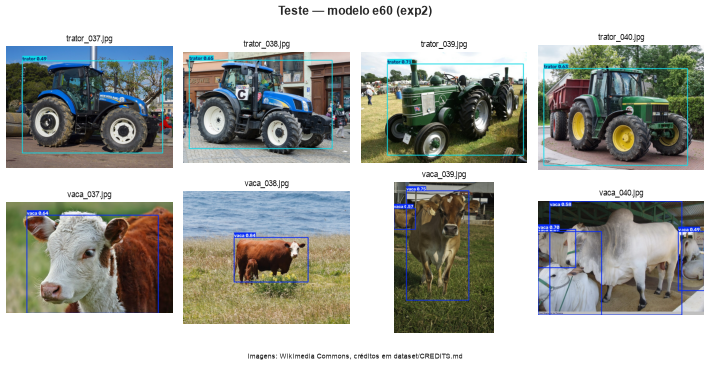

In [18]:
GRID_COLUMNS = 4
GRID_CELL = 3.0
GRID_DPI = 60
SAVED_GRID_DPI = 85
GRID_TITLE_SIZE = 9
CAPTION_SIZE = 8
CAPTION_MARGIN = 0.04
IMAGE_CAPTION = "Imagens: Wikimedia Commons, créditos em dataset/CREDITS.md"
FIGURES_DIR = PROJECT_DIR / "docs" / "figuras"
BEST_GRID_FILE = FIGURES_DIR / "teste_melhor_modelo.png"


def show_grid(folder: Path, title: str, save_to: Path | None = None) -> None:
    images = sorted(folder.glob(f"*{IMAGE_SUFFIX}"))
    rows = -(-len(images) // GRID_COLUMNS)
    fig, axes = plt.subplots(rows, GRID_COLUMNS, figsize=(GRID_CELL * GRID_COLUMNS, GRID_CELL * rows), dpi=GRID_DPI, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, images):
        ax.imshow(mpimg.imread(image))
        ax.set_title(image.name, fontsize=GRID_TITLE_SIZE)
    fig.suptitle(title, fontweight="bold")
    fig.text(0.5, 0, IMAGE_CAPTION, ha="center", fontsize=CAPTION_SIZE)
    fig.tight_layout(rect=(0, CAPTION_MARGIN, 1, 1))
    if save_to is not None:
        save_to.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_to, dpi=SAVED_GRID_DPI, bbox_inches="tight")
        print(f"Figura salva em {save_to} ({save_to.stat().st_size // 1024} KB)")
    render(fig)


show_grid(DETECTIONS.loc[BEST, "pasta"], f"Teste — modelo {BEST} ({DETECTIONS.loc[BEST, 'pasta'].name})", BEST_GRID_FILE)

### 6.4 Mesmas imagens com o outro modelo
Para a comparação visual, a mesma grade com a outra simulação.

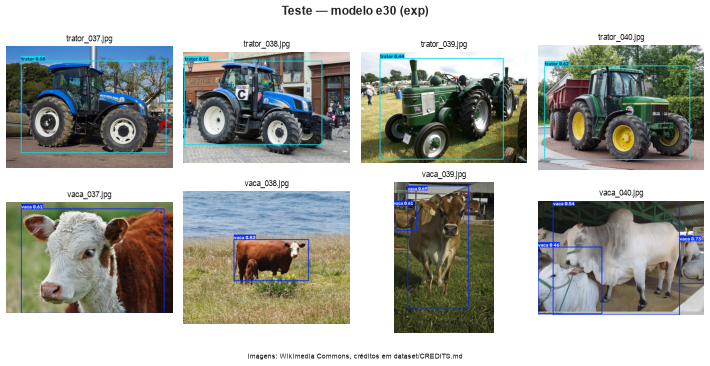

In [19]:
for name in EPOCH_PLAN:
    if name != BEST:
        show_grid(DETECTIONS.loc[name, "pasta"], f"Teste — modelo {name} ({DETECTIONS.loc[name, 'pasta'].name})")

### 6.5 Persistência dos resultados no Google Drive
No Colab, a pasta `/content/yolov5` é apagada quando a sessão termina. Por isso, copiamos para `resultados_yolo/`, na pasta do projeto no Drive, o que é necessário para revisar a entrega depois:
- de cada treino: `results.csv`, gráficos `.png` e `weights/best.pt`;
- as pastas `detect/expX` com as imagens anotadas.

`annotated_folder` devolve a pasta definitiva das imagens anotadas de cada modelo: a cópia no Drive, no Colab, e `yolov5/runs/detect/expX`, localmente, onde `yolov5/runs` já é persistente.

In [20]:
PERSIST_DIR = PROJECT_DIR / "resultados_yolo"
TRAIN_ARTIFACTS = ("results.csv", "*.png", "weights/best.pt")


def persist_results() -> None:
    for name in EPOCH_PLAN:
        source = RUNS_DIR / "train" / name
        for pattern in TRAIN_ARTIFACTS:
            for path in source.glob(pattern):
                target = PERSIST_DIR / "train" / name / path.relative_to(source)
                target.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(path, target)
    for folder in DETECTIONS["pasta"]:
        shutil.copytree(folder, PERSIST_DIR / "detect" / folder.name, dirs_exist_ok=True)


def annotated_folder(name: str) -> Path:
    folder = DETECTIONS.loc[name, "pasta"]
    return PERSIST_DIR / "detect" / folder.name if IN_COLAB else folder


if IN_COLAB:
    persist_results()
    print(f"Resultados copiados para {PERSIST_DIR}")
else:
    print(f"Execução local: resultados já persistidos em {RUNS_DIR}")

Execução local: resultados já persistidos em C:\Users\leelt\fiap-fase6\yolov5\runs


## 7. Conclusões

Todos os números e comparações desta seção são **gerados a partir dos resultados da execução atual**. Assim, o texto continua correto se o notebook for executado de novo, por exemplo após revisar os rótulos no Make Sense. A interpretação qualitativa vem logo depois.

### 7.1 Funções do relatório
- `versus` compara uma métrica entre os dois modelos e escreve quem leva vantagem. Diferenças de até 5 % do maior valor contam como empate, porque com 8 imagens por split uma única caixa muda a métrica nessa ordem.
- `box_gap` mede a distância entre a *box loss* de validação e a de treino, um indicador de *overfitting*.
- `show_markdown` exibe uma lista de frases como Markdown formatado.
- Os números usam vírgula decimal (`fmt_num`).

In [21]:
TIE_TOLERANCE = 0.05
SHORT_RUN, LONG_RUN = EPOCH_PLAN
SCORE_TABLE = EVALUATION.set_index(["split", "modelo"])
CLASS_SCORE_COLUMNS = {f"mAP50-95 {cls}": cls for cls in CLASS_NAMES}
MAP_HISTORY_COLUMN = "metrics/mAP_0.5:0.95"
MS_PER_SECOND = 1000
LOSS_DIGITS = 4
TIME_RESOLUTION_S = 3.6


def final_values(column: str) -> dict[str, float]:
    return {name: HISTORY[name][column].iloc[-1] for name in EPOCH_PLAN}


def split_values(split: str, metric: str) -> dict[str, float]:
    return SCORE_TABLE.loc[split][metric].to_dict()


def box_gap() -> dict[str, float]:
    train_box, val_box = final_values("train/box_loss"), final_values("val/box_loss")
    return {name: val_box[name] - train_box[name] for name in EPOCH_PLAN}


def is_tie(values: dict[str, float]) -> bool:
    return max(values.values()) - min(values.values()) <= TIE_TOLERANCE * max(map(abs, values.values()))


def versus(label: str, values: dict[str, float], lower_is_better: bool = False, digits: int = 3) -> str:
    detail = " × ".join(f"`{name}` {fmt_num(value, digits)}" for name, value in values.items())
    if is_tie(values):
        return f"**{label}**: praticamente igual nos dois modelos ({detail})"
    winner = (min if lower_is_better else max)(values, key=values.get)
    return f"**{label}**: vantagem de `{winner}` ({detail})"


def show_markdown(lines: list[str], title: str = "") -> None:
    heading = [f"#### {title}"] if title else []
    display(Markdown("\n".join([*heading, *(f"- {line}" for line in lines)])))

### 7.2 Validação
O que comparamos entre os dois modelos na validação:
- acurácia: P, R, mAP50 e mAP50-95;
- erro: *losses* de validação da última época;
- distância entre o erro de treino e o de validação;
- época em que cada treino atingiu o melhor mAP50-95;
- classe mais difícil.

In [22]:
def validation_lines() -> list[str]:
    lines = [versus(metric, split_values("val", metric)) for metric in HEADLINE_METRICS]
    lines += [versus(column, final_values(column), lower_is_better=True, digits=LOSS_DIGITS)
              for column in LOSS_COLUMNS if column.startswith("val/")]
    lines.append("Diferença val − treino da box_loss: " + ", ".join(
        f"`{name}` {fmt_num(gap, LOSS_DIGITS, signed=True)}" for name, gap in box_gap().items()))
    lines.append("Época do melhor mAP50-95 de validação: " + ", ".join(
        f"`{name}` {HISTORY[name][MAP_HISTORY_COLUMN].idxmax() + 1} de {EPOCH_PLAN[name]}" for name in EPOCH_PLAN))
    class_scores = SCORE_TABLE.loc["val"][list(CLASS_SCORE_COLUMNS)].mean().rename(CLASS_SCORE_COLUMNS)
    lines.append(f"Classe mais difícil: **{class_scores.idxmin()}** (mAP50-95 médio {fmt_num(class_scores.min())}); "
                 f"mais fácil: **{class_scores.idxmax()}** ({fmt_num(class_scores.max())})")
    return lines


show_markdown(validation_lines(), "Validação")

#### Validação
- **precisão (P)**: vantagem de `e30` (`e30` 0,925 × `e60` 0,833)
- **revocação (R)**: vantagem de `e30` (`e30` 0,781 × `e60` 0,719)
- **mAP50**: praticamente igual nos dois modelos (`e30` 0,818 × `e60` 0,798)
- **mAP50-95**: vantagem de `e60` (`e30` 0,491 × `e60` 0,577)
- **val/box_loss**: vantagem de `e60` (`e30` 0,0631 × `e60` 0,0532)
- **val/obj_loss**: vantagem de `e60` (`e30` 0,0174 × `e60` 0,0166)
- **val/cls_loss**: vantagem de `e60` (`e30` 0,0031 × `e60` 0,0017)
- Diferença val − treino da box_loss: `e30` +0,0150, `e60` +0,0239
- Época do melhor mAP50-95 de validação: `e30` 30 de 30, `e60` 56 de 60
- Classe mais difícil: **vaca** (mAP50-95 médio 0,381); mais fácil: **trator** (0,688)

### 7.3 Teste
O que reportamos no split de teste:
- as mesmas métricas de acurácia;
- o quanto o mAP50-95 mudou da validação para o teste (generalização);
- o resultado prático do `detect.py`: acertos de classe, número de caixas e faixa de confiança;
- as imagens em que os dois modelos discordam no número de objetos.

In [23]:
CONFIDENCE_DIGITS = 2


def detection_line(name: str) -> str:
    report = REPORTS[name]
    return (f"`{name}` (`{DETECTIONS.loc[name, 'pasta'].name}`): classe correta em {report['acerto'].sum()}/{len(report)} imagens, "
            f"{report['caixas'].sum()} caixas, maior confiança por imagem entre "
            f"{fmt_num(report['maior confiança'].min(), CONFIDENCE_DIGITS)} e {fmt_num(report['maior confiança'].max(), CONFIDENCE_DIGITS)}")


def test_lines() -> list[str]:
    lines = [versus(metric, split_values("test", metric)) for metric in HEADLINE_METRICS]
    drift = {name: SCORE_TABLE.loc["test"].loc[name, "mAP50-95"] - SCORE_TABLE.loc["val"].loc[name, "mAP50-95"] for name in EPOCH_PLAN}
    lines.append("mAP50-95 teste − validação: " + ", ".join(f"`{name}` {fmt_num(value, signed=True)}" for name, value in drift.items()))
    lines += [detection_line(name) for name in EPOCH_PLAN]
    disagreements = REPORTS[SHORT_RUN].index[REPORTS[SHORT_RUN]["caixas"] != REPORTS[LONG_RUN]["caixas"]]
    lines.append("Imagens com número de caixas diferente entre os modelos: " + (", ".join(f"`{image}`" for image in disagreements) or "nenhuma"))
    return lines


show_markdown(test_lines(), "Teste")

#### Teste
- **precisão (P)**: vantagem de `e60` (`e30` 0,748 × `e60` 0,980)
- **revocação (R)**: praticamente igual nos dois modelos (`e30` 0,764 × `e60` 0,764)
- **mAP50**: praticamente igual nos dois modelos (`e30` 0,813 × `e60` 0,804)
- **mAP50-95**: praticamente igual nos dois modelos (`e30` 0,529 × `e60` 0,534)
- mAP50-95 teste − validação: `e30` +0,037, `e60` -0,043
- `e30` (`exp`): classe correta em 8/8 imagens, 11 caixas, maior confiança por imagem entre 0,44 e 0,82
- `e60` (`exp2`): classe correta em 8/8 imagens, 12 caixas, maior confiança por imagem entre 0,49 e 0,84
- Imagens com número de caixas diferente entre os modelos: `vaca_040.jpg`

### 7.4 Desempenho (tempo)
O que reportamos sobre tempo:
- tempo total e tempo do laço de épocas de cada treino;
- quanto o dobro de épocas custou de fato e por quê;
- tempo de inferência por imagem, medido pelo `val.py` (*batch* 1) e pelo `detect.py`.

In [24]:
def scaling_line(loop: dict[str, float]) -> str:
    epoch_ratio = EPOCH_PLAN[LONG_RUN] / EPOCH_PLAN[SHORT_RUN]
    time_ratio = loop[LONG_RUN] / loop[SHORT_RUN]
    per_epoch = {name: loop[name] / EPOCH_PLAN[name] for name in EPOCH_PLAN}
    head = (f"`{LONG_RUN}` tem {epoch_ratio:.0f}× as épocas de `{SHORT_RUN}` e custou "
            f"{fmt_num(time_ratio, 2)}× o tempo do laço")
    if time_ratio >= epoch_ratio * (1 - TIE_TOLERANCE):
        return f"{head}: aproximadamente proporcional ao número de épocas"
    return (f"{head}, abaixo do proporcional: o tempo por época caiu de {fmt_num(per_epoch[SHORT_RUN], 1)} s "
            f"para {fmt_num(per_epoch[LONG_RUN], 1)} s porque custos únicos de partida (aquecimento da GPU/cuDNN, "
            f"cache do dataset, primeira época mais lenta) se diluem em mais épocas; a resolução de "
            f"{fmt_num(TIME_RESOLUTION_S, 1)} s do tempo informado pelo YOLOv5 também pesa em laços curtos")


def time_lines() -> list[str]:
    loop = {name: TRAIN_TIMES[name]["epoch_loop_s"] for name in EPOCH_PLAN}
    iterations = -(-INVENTORY.loc["train", "imagens"] // BATCH)
    detect_ms = DETECTIONS["detect.py inferência (ms/img)"]
    lines = [f"`{name}`: {TRAIN_TIMES[name]['total_s']:.0f} s no total, {loop[name]:.0f} s no laço de épocas "
             f"({fmt_num(loop[name] / EPOCH_PLAN[name], 1)} s/época, {iterations} iterações por época)" for name in EPOCH_PLAN]
    lines.append(scaling_line(loop))
    lines += [f"Inferência `{name}`: {fmt_num(COMPARISON.loc[name, 'teste inferência (ms/img)'], 1)} ms/img no `val.py` e "
              f"{fmt_num(detect_ms[name], 1)} ms/img no `detect.py`" for name in EPOCH_PLAN]
    lines.append(f"Melhor caso medido: {fmt_num(detect_ms.min(), 1)} ms/img, cerca de {MS_PER_SECOND / detect_ms.min():.0f} imagens por segundo")
    return lines


show_markdown(time_lines(), "Desempenho")

#### Desempenho
- `e30`: 74 s no total, 36 s no laço de épocas (1,2 s/época, 4 iterações por época)
- `e60`: 102 s no total, 68 s no laço de épocas (1,1 s/época, 4 iterações por época)
- `e60` tem 2× as épocas de `e30` e custou 1,90× o tempo do laço, abaixo do proporcional: o tempo por época caiu de 1,2 s para 1,1 s porque custos únicos de partida (aquecimento da GPU/cuDNN, cache do dataset, primeira época mais lenta) se diluem em mais épocas; a resolução de 3,6 s do tempo informado pelo YOLOv5 também pesa em laços curtos
- Inferência `e30`: 12,9 ms/img no `val.py` e 13,9 ms/img no `detect.py`
- Inferência `e60`: 10,9 ms/img no `val.py` e 13,9 ms/img no `detect.py`
- Melhor caso medido: 13,9 ms/img, cerca de 72 imagens por segundo

### 7.5 Modelo recomendado
Resumimos a escolha da seção 5.3 com:
- as métricas de teste do modelo escolhido;
- uma checagem de *overfitting*: se a distância val − treino cresceu no modelo escolhido, verificamos se mAP50-95 e P compensam esse sinal;
- o custo relativo de treino;
- a pasta definitiva das imagens anotadas (seção 6.5).

In [25]:
def overfitting_line(other: str) -> str:
    gap = box_gap()
    gap_detail = (f"`{other}` {fmt_num(gap[other], LOSS_DIGITS, signed=True)} → "
                  f"`{BEST}` {fmt_num(gap[BEST], LOSS_DIGITS, signed=True)}")
    if gap[BEST] <= gap[other]:
        return f"A diferença val − treino da box_loss não cresceu no modelo escolhido ({gap_detail}): sem sinal de *overfitting*"
    val_map = split_values("val", "mAP50-95")
    test_map = split_values("test", "mAP50-95")
    test_precision = split_values("test", PRECISION)
    test_holds = test_map[BEST] >= test_map[other] or is_tie(test_map)
    verdict = ("a escolha se mantém, porque o ganho de mAP50-95 na validação "
               f"({fmt_num(val_map[other])} → {fmt_num(val_map[BEST])}) não se perdeu no teste "
               f"(mAP50-95 {fmt_num(test_map[other])} → {fmt_num(test_map[BEST])}; "
               f"P {fmt_num(test_precision[other])} → {fmt_num(test_precision[BEST])})"
               if test_holds else
               f"mas o mAP50-95 de teste caiu ({fmt_num(test_map[other])} → {fmt_num(test_map[BEST])}); "
               f"com mais dados, vale reavaliar `{other}`")
    return f"A diferença val − treino da box_loss cresceu ({gap_detail}), um sinal leve de *overfitting*; {verdict}"


def choice_lines() -> list[str]:
    other = next(name for name in EPOCH_PLAN if name != BEST)
    test = SCORE_TABLE.loc["test"].loc[BEST]
    cost = TRAIN_TIMES[BEST]["epoch_loop_s"] / TRAIN_TIMES[other]["epoch_loop_s"]
    return [
        f"Modelo recomendado: **`{BEST}`** ({EPOCH_PLAN[BEST]} épocas), escolhido pelo mAP50-95 de validação",
        "No teste: " + ", ".join(f"{metric} {fmt_num(test[metric])}" for metric in HEADLINE_METRICS),
        overfitting_line(other),
        f"Custo de treino: {fmt_num(cost, 2)}× o laço de épocas de `{other}`; custo de inferência equivalente (mesma arquitetura)",
        f"Imagens anotadas para o cliente: `{annotated_folder(BEST)}`",
    ]


show_markdown(choice_lines(), "Escolha")

#### Escolha
- Modelo recomendado: **`e60`** (60 épocas), escolhido pelo mAP50-95 de validação
- No teste: precisão (P) 0,980, revocação (R) 0,764, mAP50 0,804, mAP50-95 0,534
- A diferença val − treino da box_loss cresceu (`e30` +0,0150 → `e60` +0,0239), um sinal leve de *overfitting*; a escolha se mantém, porque o ganho de mAP50-95 na validação (0,491 → 0,577) não se perdeu no teste (mAP50-95 0,529 → 0,534; P 0,748 → 0,980)
- Custo de treino: 1,90× o laço de épocas de `e30`; custo de inferência equivalente (mesma arquitetura)
- Imagens anotadas para o cliente: `C:\Users\leelt\fiap-fase6\yolov5\runs\detect\exp2`

### 7.6 Como interpretar os resultados

- **mAP50 × mAP50-95.** O mAP50 conta uma detecção como correta quando a caixa cobre pelo menos metade do objeto. O mAP50-95 exige sobreposições cada vez maiores. Se o mAP50 empata entre 30 e 60 épocas e o mAP50-95 sobe, o treino mais longo não passou a *encontrar* mais objetos: ele *ajustou melhor as caixas*.
- **Precisão (P) × revocação/recall (R).** P alta significa poucos alarmes falsos. R alta significa poucos objetos perdidos. Para a FarmTech, um alarme falso (por exemplo, avisar que há um trator onde não há) e um objeto perdido (uma vaca fora da contagem) têm custos diferentes, e o limiar de confiança deve ser ajustado conforme essa prioridade.
- ***Overfitting*.** Quando a *loss* de treino continua caindo e a de validação se afasta dela, o modelo começa a decorar o treino. Esse sinal só deve mudar a escolha se vier acompanhado de queda nas métricas de validação e de teste, e a seção 7.5 faz essa verificação. Se o mAP50-95 de teste fica próximo do de validação, a escolha do `best.pt` também não se ajustou demais à validação.
- **Oscilação.** Com 8 imagens de validação, um único acerto ou erro muda bastante as métricas. Por isso as curvas da seção 3 oscilam e diferenças pequenas entre os modelos devem ser lidas como empate.
- **Tempo de treino.** Com poucas imagens, cada época é curta, e os custos únicos de partida pesam muito: aquecimento da GPU/cuDNN, criação do cache do dataset e uma primeira época mais lenta. Em um treino mais longo, esses custos se diluem e o tempo médio por época cai. Por isso o dobro de épocas tende a custar menos que o dobro do tempo. A resolução de 3,6 s do tempo informado pelo YOLOv5 também limita a precisão dessa comparação.
- **Tempo de inferência.** Os dois modelos têm a mesma arquitetura (YOLOv5s) e, portanto, o mesmo custo por imagem: treinar mais não deixa a detecção mais lenta. Diferenças de milissegundos entre `e30` e `e60` refletem a carga da GPU no momento da medição, não o modelo.

### 7.7 Para o cliente: pontos fortes

- **Resultado visual convincente:** as imagens da seção 6.3 mostram caixa, classe e confiança, e a tabela 6.2 mostra, imagem por imagem, se a classe prevista coincide com a real.
- **Velocidade:** em GPU, a inferência leva milissegundos por imagem (seção 7.4). Isso permite processar o vídeo de câmeras de fazenda em tempo real.
- **Treino barato:** graças ao *transfer learning* a partir do `yolov5s.pt`, bastam dezenas de imagens rotuladas e alguns minutos de GPU. Uma nova classe ou um novo cliente pode ser atendido rapidamente.
- **Rotulagem ágil:** a pré-rotulagem automática seguida de revisão manual reduz o tempo de preparação do dataset sem abrir mão da conferência humana.
- **Reprodutível e portátil:** a semente e as versões do YOLOv5 e do `ultralytics` são fixas, o mesmo notebook roda no Google Colab (dados no Drive) e localmente, e os resultados ficam persistidos (seção 6.5).

### 7.8 Para o cliente: limitações e próximos passos

- **Amostra pequena:** validação e teste têm 8 imagens cada, então cada imagem pesa 12,5 % na métrica. Os números indicam viabilidade, não são garantia estatística.
- **Rebanhos e animais pequenos:** vacas sobrepostas, distantes ou parcialmente encobertas são o cenário mais difícil, e animais pequenos, como bezerros, podem não ser detectados.
- **Domínio das imagens:** as fotos vêm de um acervo público, em geral tiradas de dia e com o objeto em destaque. Câmeras fixas de fazenda, drones, visão noturna, chuva e poeira não foram avaliados. Também não há imagens sem nenhum objeto, então a taxa de alarmes falsos em cenas vazias continua desconhecida.
- **Viés da pré-rotulagem:** as caixas iniciais vieram de outros detectores. A revisão manual corrige os erros, mas pode herdar o estilo de enquadramento desses modelos.
- **Precisão das caixas:** o mAP50-95 abaixo do mAP50 mostra que as caixas servem para presença e contagem, mas ainda não para medições, como estimar o tamanho de um animal.
- **Próximos passos:**
  - coletar algumas centenas de imagens por classe nas câmeras reais do cliente;
  - incluir imagens negativas e de rebanhos densos;
  - usar aumento de dados e avaliar o YOLOv5m;
  - usar *early stopping* (`--patience`) em vez de fixar o número de épocas.

# Entrega 2 — Comparativo: YOLO customizado × YOLO tradicional × CNN do zero

## 8. Configuração da Entrega 2

Usamos **o mesmo dataset da Entrega 1** (vacas e tratores, split 64/8/8) para comparar três abordagens:

1. **YOLO customizado**: o YOLOv5s treinado nas seções anteriores, com uma variante por entrada de `EPOCH_PLAN`;
2. **YOLO tradicional**: o YOLOv5s pré-treinado no COCO, **sem nenhuma customização**;
3. **CNN treinada do zero**: uma rede convolucional pequena em Keras/TensorFlow, que apenas **classifica** a imagem (vaca ou trator).

Critérios: facilidade de uso/integração, precisão do modelo, tempo de treinamento/customização e tempo de inferência. Esta parte reaproveita as variáveis da Entrega 1 (`DATA_ROOT`, `YOLO_DIR`, `RUNS_DIR`, `CLASS_NAMES`, `CONF_THRES`, `SEED`, `EPOCH_PLAN`, `TRAIN_TIMES`, `SPLITS`, `IMAGE_SUFFIX`) e suas funções auxiliares (`render`, `show_markdown`, `fmt_num`, `class_from_name`, `best_weights`, `quiet_yolo`).

### 8.1 Bibliotecas, sementes e constantes
Importamos só o que a Entrega 1 ainda não carregou (TensorFlow, scikit-learn, PIL). O TensorFlow é configurado **antes de qualquer operação**: crescimento de memória sob demanda na GPU, para dividir a placa com o PyTorch, operações determinísticas e logs silenciados. Também fixamos as sementes de Python, NumPy, PyTorch e TensorFlow.

In [26]:
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import random
from dataclasses import dataclass

import tensorflow as tf
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix

tf.get_logger().setLevel("ERROR")

NO_DETECTION = "nenhum"
IOU_MATCH = 0.5
DECISION_THRESHOLD = 0.5
TIMING_RUNS = 5
WARMUP_RUNS = 2
PRED_GRID_COLUMNS = 4
CONFUSION_PANEL = (4.5, 4)
TORCH_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def configure_tensorflow() -> str:
    gpus = tf.config.list_physical_devices("GPU")
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError as error:
            print(f"Crescimento de memória não aplicado em {gpu.name} (GPU já inicializada): {error}")
    try:
        tf.config.experimental.enable_op_determinism()
    except RuntimeError as error:
        print(f"Determinismo de operações não ativado (TensorFlow já inicializado): {error}")
    return "GPU" if gpus else "CPU"


def set_seeds(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    tf.keras.utils.set_random_seed(seed)


TF_DEVICE = configure_tensorflow()
set_seeds()
print(f"TensorFlow {tf.__version__} em {TF_DEVICE} | PyTorch em {TORCH_DEVICE}")

TensorFlow 2.19.0 em CPU | PyTorch em cuda


### 8.2 Leitura do dataset
A classe de cada imagem vem do prefixo do nome do arquivo (`vaca_NNN.jpg` / `trator_NNN.jpg`). As caixas verdadeiras vêm dos rótulos YOLO e são convertidas para pixels.

Além do teste, avaliamos a classificação por imagem em **validação + teste**, para ter um pouco mais de suporte estatístico. **Atenção ao viés:** a validação serviu para escolher o modelo no YOLO customizado (`best.pt`) e na CNN (*early stopping* e arquitetura). Nessas duas abordagens a acurácia em val+teste tende a ser otimista; o YOLO tradicional nunca viu nenhuma dessas imagens.

In [27]:
Detection = tuple[str, float, list[float]]
def list_split(split: str) -> list[Path]:
    return sorted((DATA_ROOT / "images" / split).glob(f"*{IMAGE_SUFFIX}"))


def yolo_to_pixels(xc: float, yc: float, w: float, h: float, width: int, height: int) -> list[float]:
    return [(xc - w / 2) * width, (yc - h / 2) * height, (xc + w / 2) * width, (yc + h / 2) * height]


def read_gt_boxes(image_path: Path) -> list[tuple[str, list[float]]]:
    label_path = DATA_ROOT / "labels" / image_path.parent.name / f"{image_path.stem}.txt"
    width, height = Image.open(image_path).size
    rows = [line.split() for line in label_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    return [(CLASS_NAMES[int(cls)], yolo_to_pixels(*map(float, coords), width, height)) for cls, *coords in rows]


SPLIT_PATHS = {split: list_split(split) for split in SPLITS}
TEST_PATHS = SPLIT_PATHS["test"]
VAL_TEST_PATHS = SPLIT_PATHS["val"] + TEST_PATHS
Y_TEST = [class_from_name(p) for p in TEST_PATHS]
Y_VAL_TEST = [class_from_name(p) for p in VAL_TEST_PATHS]
GT_TEST = {p.name: read_gt_boxes(p) for p in TEST_PATHS}
TEST_LABEL = f"teste (n={len(Y_TEST)})"
VAL_TEST_LABEL = f"val+teste (n={len(Y_VAL_TEST)})"
pd.DataFrame({split: pd.Series([class_from_name(p) for p in paths]).value_counts() for split, paths in SPLIT_PATHS.items()}).fillna(0).astype(int)

,train,val,test
trator,32,4,4
vaca,32,4,4


### 8.3 Funções de avaliação comuns
As três abordagens usam as mesmas funções, para que as métricas sejam comparáveis:
- `measure_inference_ms`: mediana do tempo por imagem, **do arquivo até a predição** (inclui leitura e pré-processamento), depois de um aquecimento;
- `match_detections`: casa detecções e caixas verdadeiras da mesma classe com IoU ≥ 0,5 (guloso, por confiança) e devolve verdadeiros positivos (VP), falsos positivos (FP) e falsos negativos (FN);
- `wilson_interval`: intervalo de confiança de 95% de Wilson para uma proporção, essencial com tão poucas imagens.

In [28]:
def timed_call_ms(predict_fn, path: Path) -> float:
    start = time.perf_counter()
    predict_fn(path)
    return (time.perf_counter() - start) * 1000


def measure_inference_ms(predict_fn, paths: list[Path]) -> float:
    for path in paths[:WARMUP_RUNS]:
        predict_fn(path)
    return float(np.median([timed_call_ms(predict_fn, path) for _ in range(TIMING_RUNS) for path in paths]))


def box_area(box: list[float]) -> float:
    return (box[2] - box[0]) * (box[3] - box[1])


def iou(box_a: list[float], box_b: list[float]) -> float:
    ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    return inter / (box_area(box_a) + box_area(box_b) - inter + 1e-9)


def match_detections(detections: list[Detection], gt_boxes: list[tuple[str, list[float]]]) -> tuple[int, int, int]:
    unmatched = list(gt_boxes)
    true_positives = 0
    for label, _, box in sorted(detections, key=lambda d: -d[1]):
        candidates = [(iou(box, gt_box), i) for i, (gt_label, gt_box) in enumerate(unmatched) if gt_label == label]
        best = max(candidates, default=(0.0, None))
        if best[0] >= IOU_MATCH:
            unmatched.pop(best[1])
            true_positives += 1
    return true_positives, len(detections) - true_positives, len(unmatched)


def detection_metrics(detections_by_image: dict[str, list[Detection]]) -> dict:
    tp, fp, fn = np.sum([match_detections(dets, GT_TEST[name]) for name, dets in detections_by_image.items()], axis=0)
    return {"VP": int(tp), "FP": int(fp), "FN": int(fn),
            "precisao_det": tp / (tp + fp) if tp + fp else 0.0,
            "revocacao_det": tp / (tp + fn) if tp + fn else 0.0}


def wilson_interval(hits: int, total: int, z: float = 1.96) -> tuple[float, float]:
    p = hits / total
    center = (p + z**2 / (2 * total)) / (1 + z**2 / total)
    margin = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / (1 + z**2 / total)
    return center - margin, center + margin


def show_confusion(y_true: list[str], y_pred: list[str], title: str, ax: plt.Axes) -> None:
    labels = CLASS_NAMES + ([NO_DETECTION] if NO_DETECTION in y_pred else [])
    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    ConfusionMatrixDisplay(matrix, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)

### 8.4 Utilitários para modelos YOLOv5
Carregamos os modelos YOLOv5 via `torch.hub` a partir do clone local, com os banners do YOLOv5 silenciados. Cada imagem passa **uma única vez** pelo modelo; a saída bruta (classes do próprio modelo) é guardada e depois traduzida para o vocabulário do nosso problema. A predição **por imagem** é a classe da detecção de maior confiança. Sem detecção válida, a imagem recebe `nenhum`, que conta como erro.

In [29]:
def load_yolo(weights: Path) -> torch.nn.Module:
    with quiet_yolo():
        model = torch.hub.load(str(YOLO_DIR), "custom", path=str(weights), source="local", verbose=False).to(TORCH_DEVICE)
    model.conf = CONF_THRES
    return model


def raw_detections(model: torch.nn.Module, path: Path) -> list[Detection]:
    rows = model(str(path)).xyxy[0].tolist()
    return [(model.names[int(c)], conf, [x1, y1, x2, y2]) for x1, y1, x2, y2, conf, c in rows]


def map_detections(raw: list[Detection], class_map: dict[str, str]) -> list[Detection]:
    return [(class_map[label], conf, box) for label, conf, box in raw if label in class_map]


def top_class(detections: list[Detection]) -> str:
    return max(detections, key=lambda d: d[1])[0] if detections else NO_DETECTION


def evaluate_yolo(model: torch.nn.Module, class_map: dict[str, str]) -> dict:
    raw = {p.name: raw_detections(model, p) for p in VAL_TEST_PATHS}
    mapped = {name: map_detections(dets, class_map) for name, dets in raw.items()}
    test_detections = {p.name: mapped[p.name] for p in TEST_PATHS}
    return {"raw": raw, "detections": test_detections, "params": sum(p.numel() for p in model.parameters()),
            "y_pred": [top_class(mapped[p.name]) for p in TEST_PATHS],
            "y_pred_val_test": [top_class(mapped[p.name]) for p in VAL_TEST_PATHS],
            "ms": measure_inference_ms(lambda p: model(str(p)), TEST_PATHS),
            **detection_metrics(test_detections)}


def summarize_yolo(name: str, result: dict) -> None:
    print(f"{name}: acurácia {TEST_LABEL} = {fmt_num(accuracy_score(Y_TEST, result['y_pred']), 3)} | "
          f"{VAL_TEST_LABEL} = {fmt_num(accuracy_score(Y_VAL_TEST, result['y_pred_val_test']), 3)} | "
          f"detecção VP={result['VP']} FP={result['FP']} FN={result['FN']} "
          f"precisão={fmt_num(result['precisao_det'], 3)} revocação={fmt_num(result['revocacao_det'], 3)} | {fmt_num(result['ms'], 1)} ms/img")
    print(classification_report(Y_TEST, result["y_pred"], labels=CLASS_NAMES, zero_division=0))

## 9. YOLO tradicional (YOLOv5s pré-treinado no COCO, sem customização)
O COCO tem a classe `cow`, mas **não tem `tractor`**. Para tentar aproveitar o modelo sem treino, mapeamos `cow → vaca` e, para `trator`, os veículos terrestres mais parecidos (`truck`, `car`, `bus`). As demais classes do COCO são ignoradas. A tabela mostra, para cada imagem de teste, a predição mapeada e as detecções brutas do COCO.

In [30]:
COW_CLASS, TRACTOR_CLASS = CLASS_NAMES
COCO_TO_OURS = {"cow": COW_CLASS, "truck": TRACTOR_CLASS, "car": TRACTOR_CLASS, "bus": TRACTOR_CLASS}
COCO_WEIGHTS = YOLO_DIR / "yolov5s.pt"
RAW_CONF_DIGITS = 2

coco_result = evaluate_yolo(load_yolo(COCO_WEIGHTS), COCO_TO_OURS)
pd.DataFrame({"real": Y_TEST, "predito (mapeado)": coco_result["y_pred"],
              "detecções COCO brutas": [[(label, round(conf, RAW_CONF_DIGITS)) for label, conf, _ in coco_result["raw"][p.name]]
                                        for p in TEST_PATHS]},
             index=[p.name for p in TEST_PATHS])

,real,predito (mapeado),detecções COCO brutas
trator_037.jpg,trator,trator,"[(person, 0.85), (person, 0.74), (truck, 0.69)..."
trator_038.jpg,trator,trator,"[(person, 0.87), (person, 0.84), (truck, 0.76)..."
trator_039.jpg,trator,trator,"[(person, 0.79), (truck, 0.51), (truck, 0.29),..."
trator_040.jpg,trator,trator,"[(truck, 0.6)]"
vaca_037.jpg,vaca,vaca,"[(cow, 0.4)]"
vaca_038.jpg,vaca,vaca,"[(cow, 0.93), (bird, 0.45)]"
vaca_039.jpg,vaca,vaca,"[(cow, 0.88), (cow, 0.38)]"
vaca_040.jpg,vaca,vaca,"[(cow, 0.79), (cow, 0.75), (cow, 0.73)]"


### 9.1 Métricas do YOLO tradicional
Acurácia por imagem (teste e val+teste), relatório de classificação do teste e precisão/revocação (*recall*) de **detecção** (IoU ≥ 0,5) contra os nossos rótulos de teste.

In [31]:
summarize_yolo("YOLO tradicional (COCO)", coco_result)

YOLO tradicional (COCO): acurácia teste (n=8) = 1,000 | val+teste (n=16) = 0,938 | detecção VP=11 FP=1 FN=5 precisão=0,917 revocação=0,688 | 15,3 ms/img
              precision    recall  f1-score   support

        vaca       1.00      1.00      1.00         4
      trator       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



## 10. YOLO customizado (Entrega 1)
Recarregamos o `best.pt` de cada treino de `EPOCH_PLAN` e o avaliamos **com o mesmo procedimento** do YOLO tradicional: classe da detecção mais confiante por imagem, precisão/revocação de detecção e tempo de inferência.

In [32]:
IDENTITY_MAP = {name: name for name in CLASS_NAMES}


custom_results = {run: evaluate_yolo(load_yolo(best_weights(run)), IDENTITY_MAP) for run in EPOCH_PLAN}
for run, result in custom_results.items():
    summarize_yolo(f"YOLO customizado ({run})", result)

YOLO customizado (e30): acurácia teste (n=8) = 1,000 | val+teste (n=16) = 1,000 | detecção VP=11 FP=0 FN=5 precisão=1,000 revocação=0,688 | 15,2 ms/img
              precision    recall  f1-score   support

        vaca       1.00      1.00      1.00         4
      trator       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8

YOLO customizado (e60): acurácia teste (n=8) = 1,000 | val+teste (n=16) = 1,000 | detecção VP=11 FP=1 FN=5 precisão=0,917 revocação=0,688 | 14,8 ms/img
              precision    recall  f1-score   support

        vaca       1.00      1.00      1.00         4
      trator       1.00      1.00      1.00         4

    accuracy                           1.00         8
   macro avg       1.00      1.00      1.00         8
weighted avg       1.00      1.00      1.00         8



### 10.1 Tempo de treinamento do YOLO customizado
Reaproveitamos o tempo cronometrado na Entrega 1 (`TRAIN_TIMES`): tempo total do processo de treino e duração só do laço de épocas.

In [33]:
SECONDS_PER_MINUTE = 60


def format_minutes(seconds: float | None) -> str:
    return f"{fmt_num(seconds / SECONDS_PER_MINUTE, 1)} min" if seconds is not None else "N/A"


def custom_train_seconds(run: str) -> float | None:
    return TRAIN_TIMES.get(run, {}).get("total_s")


pd.DataFrame.from_dict(TRAIN_TIMES, orient="index").rename(
    columns={"epochs": "épocas", "total_s": "treino total (s)", "epoch_loop_s": "laço de épocas (s)"}).round(1)

,épocas,treino total (s),laço de épocas (s)
e30,30,73.7,36.0
e60,60,102.2,68.4


## 11. CNN treinada do zero (Keras/TensorFlow)
### 11.1 Preparação dos dados
As imagens são redimensionadas para `CNN_IMG_SIZE × CNN_IMG_SIZE` e o rótulo vem do nome do arquivo (`vaca = 0`, `trator = 1`). O split é o mesmo da Entrega 1: 64 treino / 8 validação / 8 teste.

In [34]:
CNN_IMG_SIZE = 128
CNN_BATCH_SIZE = 16
CNN_MAX_EPOCHS = 150
CNN_PATIENCE = 20
CNN_MIN_EPOCHS = 30
CNN_FILTERS = (32, 64, 128)
CNN_KERNEL = 3
CNN_DROPOUT = 0.3
CNN_LEARNING_RATE = 1e-3
AUG_ROTATION = 0.1
AUG_ZOOM = 0.15
AUG_CONTRAST = 0.2
CNN_SEEDS = (SEED, 7, 123, 2024, 31337)


def load_image_array(path: Path) -> np.ndarray:
    return np.asarray(Image.open(path).convert("RGB").resize((CNN_IMG_SIZE, CNN_IMG_SIZE)), dtype=np.float32)


def load_split_arrays(paths: list[Path]) -> tuple[np.ndarray, np.ndarray]:
    return np.stack([load_image_array(p) for p in paths]), np.array([CLASS_NAMES.index(class_from_name(p)) for p in paths])


(x_train, y_train), (x_val, y_val), (x_test, y_test) = (load_split_arrays(SPLIT_PATHS[s]) for s in SPLITS)
x_val_test, y_val_test = np.concatenate([x_val, x_test]), np.concatenate([y_val, y_test])
print(f"treino {x_train.shape} | validação {x_val.shape} | teste {x_test.shape}")

treino (64, 128, 128, 3) | validação (8, 128, 128, 3) | teste (8, 128, 128, 3)


### 11.2 Arquitetura
Uma rede pequena, adequada a 64 imagens de treino:
- camadas de *data augmentation* (flip, rotação, zoom, contraste), ativas só no treino;
- três blocos `Conv2D + MaxPooling` com 32, 64 e 128 filtros;
- `GlobalAveragePooling`, `Dropout` e saída sigmoide (vaca × trator).

A configuração foi escolhida olhando **apenas a validação**. Uma variante com `BatchNormalization` testada durante o desenvolvimento colapsou para prever sempre a mesma classe: com lotes de 16 imagens, as estatísticas do BatchNorm ficam instáveis. A tabela abaixo lista as camadas e o número de parâmetros.

In [35]:
def build_cnn() -> tf.keras.Model:
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(AUG_ROTATION),
        tf.keras.layers.RandomZoom(AUG_ZOOM),
        tf.keras.layers.RandomContrast(AUG_CONTRAST),
    ], name="augmentation")
    conv_blocks = [layer for filters in CNN_FILTERS for layer in (
        tf.keras.layers.Conv2D(filters, CNN_KERNEL, padding="same", activation="relu"),
        tf.keras.layers.MaxPooling2D(),
    )]
    model = tf.keras.Sequential([
        tf.keras.Input((CNN_IMG_SIZE, CNN_IMG_SIZE, 3)),
        augmentation,
        tf.keras.layers.Rescaling(1.0 / 255),
        *conv_blocks,
        tf.keras.layers.GlobalAveragePooling2D(),
        tf.keras.layers.Dropout(CNN_DROPOUT),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(CNN_LEARNING_RATE), loss="binary_crossentropy", metrics=["accuracy"])
    return model


def layer_table(model: tf.keras.Model) -> pd.DataFrame:
    rows = [{"camada": layer.name, "tipo": type(layer).__name__, "parâmetros": layer.count_params()} for layer in model.layers]
    return pd.DataFrame(rows).set_index("camada")


set_seeds()
CNN_LAYERS = layer_table(build_cnn())
print(f"Total de parâmetros: {fmt_num(int(CNN_LAYERS['parâmetros'].sum()), 0)}")
CNN_LAYERS

Total de parâmetros: 93377


,tipo,parâmetros
camada,,
augmentation,Sequential,0
rescaling,Rescaling,0
conv2d,Conv2D,896
max_pooling2d,MaxPooling2D,0
conv2d_1,Conv2D,18496
max_pooling2d_1,MaxPooling2D,0
conv2d_2,Conv2D,73856
max_pooling2d_2,MaxPooling2D,0
global_average_pooling2d,GlobalAveragePooling2D,0


### 11.3 Treinamento com *early stopping*
Monitoramos a perda de validação. O treino para após `CNN_PATIENCE` épocas sem melhora e restaura os melhores pesos; a contagem só começa na época `CNN_MIN_EPOCHS`, para não parar no ruído inicial. O tempo de treino é cronometrado.

Os limites `CNN_MAX_EPOCHS = 150` e `CNN_PATIENCE = 20` mantêm baixo o custo total das 5 sementes da seção 11.6, mesmo sem GPU. Com só 8 imagens de validação, a perda de validação oscila muito de uma época para outra, então épocas extras tendem a acrescentar pouco. Este primeiro treino usa a semente principal (`SEED`); o modelo resultante aparece nas curvas, nas matrizes de confusão e na grade de predições.

In [36]:
def train_cnn(seed: int) -> dict:
    set_seeds(seed)
    model = build_cnn()
    early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=CNN_PATIENCE,
                                                      restore_best_weights=True, start_from_epoch=CNN_MIN_EPOCHS)
    start = time.perf_counter()
    history = model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=CNN_MAX_EPOCHS,
                        batch_size=CNN_BATCH_SIZE, callbacks=[early_stopping], verbose=0)
    return {"model": model, "history": history.history, "seconds": time.perf_counter() - start,
            "epochs": len(history.history["loss"]), "best_epoch": early_stopping.best_epoch + 1}


main_run = train_cnn(SEED)
cnn = main_run["model"]
print(f"Épocas executadas: {main_run['epochs']} | melhor época: {main_run['best_epoch']} | "
      f"tempo: {fmt_num(main_run['seconds'], 1)} s ({TF_DEVICE})")

Épocas executadas: 65 | melhor época: 45 | tempo: 15,3 s (CPU)


### 11.4 Curvas de treinamento
Perda e acurácia de treino e de validação por época. Como a validação tem só 8 imagens, cada erro move a acurácia em 12,5 pontos, e as curvas de validação ficam naturalmente "serrilhadas".

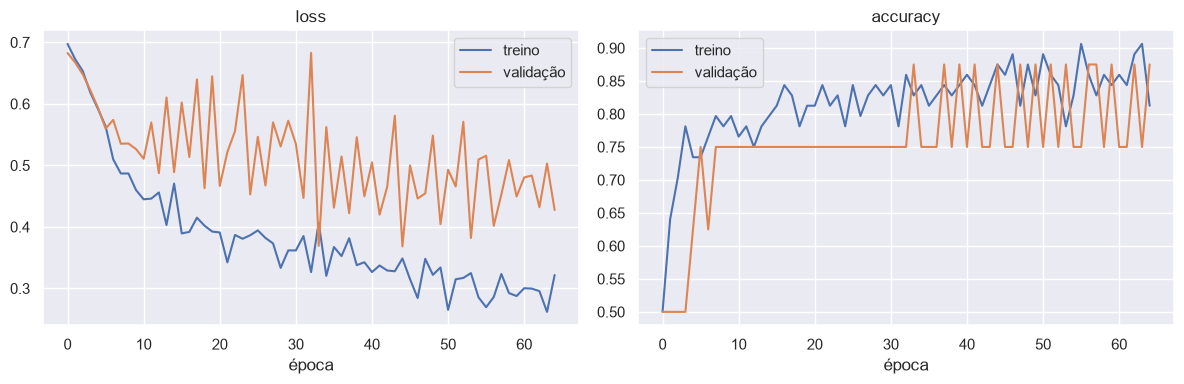

In [37]:
HISTORY_PANEL = (12, 4)


def plot_cnn_history(history: dict) -> plt.Figure:
    fig, axes = plt.subplots(1, 2, figsize=HISTORY_PANEL)
    for ax, metric in zip(axes, ("loss", "accuracy")):
        ax.plot(history[metric], label="treino")
        ax.plot(history[f"val_{metric}"], label="validação")
        ax.set_title(metric)
        ax.set_xlabel("época")
        ax.legend()
    fig.tight_layout()
    return fig


render(plot_cnn_history(main_run["history"]))

### 11.5 Avaliação da CNN (semente principal) no teste
Acurácia, relatório de classificação e tempo de inferência por imagem, medido com a mesma função usada nos modelos YOLO (do arquivo à predição).

In [38]:
def cnn_probabilities(model: tf.keras.Model, x: np.ndarray) -> np.ndarray:
    return model(x, training=False).numpy()[:, 0]


def cnn_predict_label(model: tf.keras.Model, path: Path) -> str:
    probability = cnn_probabilities(model, load_image_array(path)[None])[0]
    return CLASS_NAMES[int(probability >= DECISION_THRESHOLD)]


cnn_y_pred = [cnn_predict_label(cnn, p) for p in TEST_PATHS]
cnn_ms = measure_inference_ms(lambda p: cnn_predict_label(cnn, p), TEST_PATHS)
print(f"CNN (semente {SEED}): acurácia {TEST_LABEL} = {fmt_num(accuracy_score(Y_TEST, cnn_y_pred), 3)} | {fmt_num(cnn_ms, 1)} ms/img ({TF_DEVICE})")
print(classification_report(Y_TEST, cnn_y_pred, labels=CLASS_NAMES, zero_division=0))

CNN (semente 42): acurácia teste (n=8) = 0,875 | 17,0 ms/img (CPU)
              precision    recall  f1-score   support

        vaca       1.00      0.75      0.86         4
      trator       0.80      1.00      0.89         4

    accuracy                           0.88         8
   macro avg       0.90      0.88      0.87         8
weighted avg       0.90      0.88      0.87         8



### 11.6 Robustez da CNN: várias sementes
Com 8 imagens de validação, a época escolhida pelo *early stopping* depende muito do acaso. Retreinamos a **mesma arquitetura, com os mesmos splits**, usando as sementes de `CNN_SEEDS`. Medimos a acurácia em validação, teste e val+teste de cada uma e resumimos com média, desvio-padrão (dp), mínimo e máximo. A tabela comparativa usa a **média entre sementes**, não o resultado de uma semente só.

In [39]:
def cnn_accuracy(model: tf.keras.Model, x: np.ndarray, y: np.ndarray) -> float:
    return float(np.mean((cnn_probabilities(model, x) >= DECISION_THRESHOLD) == y))


def seed_summary(seed: int, run: dict) -> dict:
    return {"semente": seed, "épocas": run["epochs"], "melhor época": run["best_epoch"],
            "treino (s)": round(run["seconds"], 1),
            "acurácia val": cnn_accuracy(run["model"], x_val, y_val),
            "acurácia teste": cnn_accuracy(run["model"], x_test, y_test),
            "acurácia val+teste": cnn_accuracy(run["model"], x_val_test, y_val_test)}


SEED_METRICS = ["acurácia val", "acurácia teste", "acurácia val+teste", "treino (s)"]
cnn_runs = {SEED: main_run, **{seed: train_cnn(seed) for seed in CNN_SEEDS if seed != SEED}}
CNN_SEED_TABLE = pd.DataFrame([seed_summary(seed, run) for seed, run in cnn_runs.items()]).set_index("semente")
CNN_SEED_STATS = CNN_SEED_TABLE[SEED_METRICS].agg(["mean", "std", "min", "max"]).rename(
    index={"mean": "média", "std": "dp", "min": "mín", "max": "máx"})
display(CNN_SEED_TABLE)
CNN_SEED_STATS.round(3)

,épocas,melhor época,treino (s),acurácia val,acurácia teste,acurácia val+teste
semente,,,,,,
42,65,45,15.3,0.875,0.875,0.8750
7,122,102,30.9,1.000,1.000,1.0000
123,150,149,36.5,0.875,1.000,0.9375
2024,107,87,26.5,0.875,1.000,0.9375
31337,139,119,32.7,1.000,1.000,1.0000


,acurácia val,acurácia teste,acurácia val+teste,treino (s)
média,0.925,0.975,0.950,28.380
dp,0.068,0.056,0.052,8.148
mín,0.875,0.875,0.875,15.300
máx,1.000,1.000,1.000,36.500


## 12. Comparação lado a lado e análise crítica
### 12.1 Detecção por imagem (modelos YOLO)
Para cada modelo YOLO e cada imagem de teste: verdadeiros positivos, falsos positivos e falsos negativos (IoU ≥ 0,5), ao lado do número de caixas reais.

In [40]:
def match_summary(detections: list[Detection], gt_boxes: list[tuple[str, list[float]]]) -> str:
    tp, fp, fn = match_detections(detections, gt_boxes)
    return f"VP={tp} FP={fp} FN={fn}"


YOLO_RESULTS = {**{f"YOLO customizado ({run})": result for run, result in custom_results.items()},
                "YOLO tradicional (COCO)": coco_result}
per_image = pd.DataFrame({name: [match_summary(result["detections"][p.name], GT_TEST[p.name]) for p in TEST_PATHS]
                          for name, result in YOLO_RESULTS.items()}, index=[p.name for p in TEST_PATHS])
per_image.insert(0, "caixas reais", [len(GT_TEST[p.name]) for p in TEST_PATHS])
per_image

,caixas reais,YOLO customizado (e30),YOLO customizado (e60),YOLO tradicional (COCO)
trator_037.jpg,1,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0
trator_038.jpg,1,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0
trator_039.jpg,2,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1,VP=1 FP=1 FN=1
trator_040.jpg,1,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0,VP=1 FP=0 FN=0
vaca_037.jpg,2,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1
vaca_038.jpg,2,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1,VP=1 FP=0 FN=1
vaca_039.jpg,2,VP=2 FP=0 FN=0,VP=2 FP=0 FN=0,VP=2 FP=0 FN=0
vaca_040.jpg,5,VP=3 FP=0 FN=2,VP=3 FP=1 FN=2,VP=3 FP=0 FN=2


### 12.2 Matrizes de confusão
As mesmas imagens de teste para todas as abordagens. Nos modelos YOLO aparece a coluna `nenhum` quando uma imagem fica sem detecção válida.

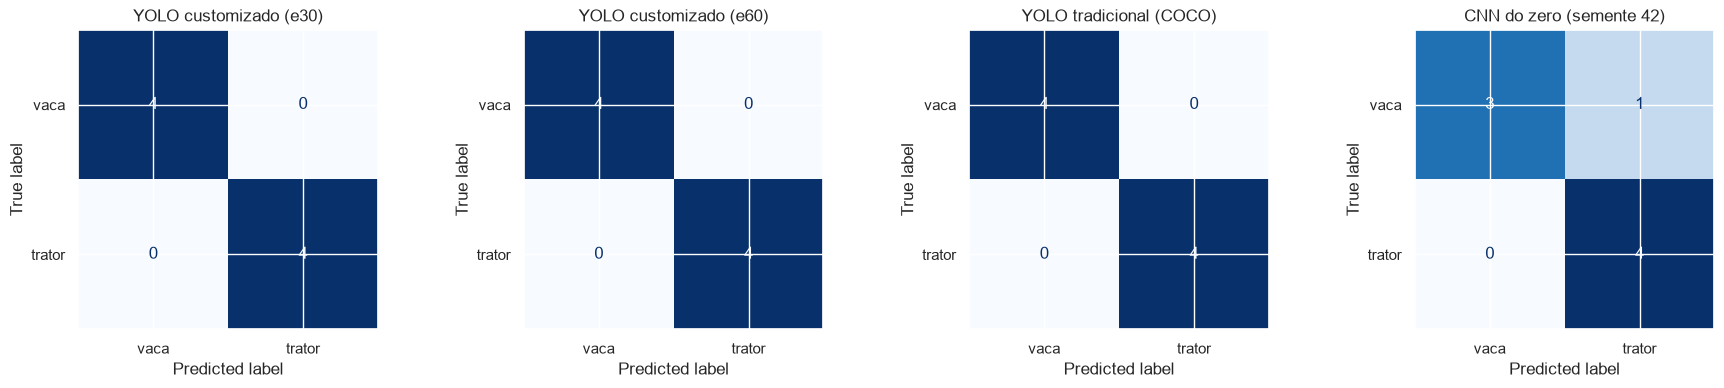

In [41]:
TEST_PREDICTIONS = {**{name: result["y_pred"] for name, result in YOLO_RESULTS.items()},
                    f"CNN do zero (semente {SEED})": cnn_y_pred}


def plot_confusions(predictions: dict[str, list[str]]) -> plt.Figure:
    fig, axes = plt.subplots(1, len(predictions), figsize=(CONFUSION_PANEL[0] * len(predictions), CONFUSION_PANEL[1]))
    for ax, (name, pred) in zip(np.atleast_1d(axes), predictions.items()):
        show_confusion(Y_TEST, pred, name, ax)
    fig.tight_layout()
    return fig


render(plot_confusions(TEST_PREDICTIONS))

### 12.3 Predições por imagem de teste
Cada imagem aparece com a classe real e a predição de cada abordagem. O título fica verde quando todas acertam e vermelho quando alguma erra.

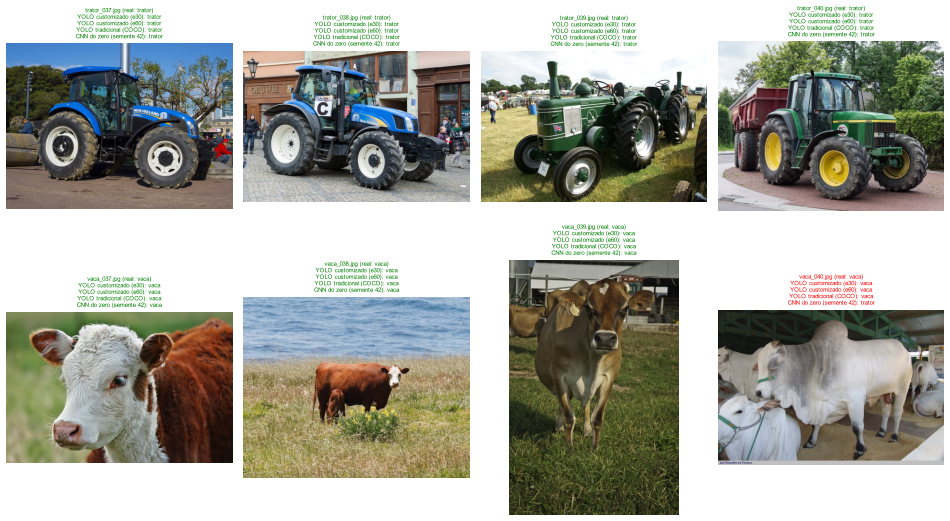

In [42]:
PRED_GRID_CELL = (4, 4.5)
PRED_GRID_FONT_SIZE = 7
PRED_GRID_DPI = 60


def plot_test_predictions(predictions: dict[str, list[str]]) -> plt.Figure:
    n_rows = -(-len(TEST_PATHS) // PRED_GRID_COLUMNS)
    fig, axes = plt.subplots(n_rows, PRED_GRID_COLUMNS, figsize=(PRED_GRID_CELL[0] * PRED_GRID_COLUMNS, PRED_GRID_CELL[1] * n_rows),
                             dpi=PRED_GRID_DPI)
    for ax in axes.flat:
        ax.axis("off")
    for index, (ax, path, truth) in enumerate(zip(axes.flat, TEST_PATHS, Y_TEST)):
        ax.imshow(Image.open(path))
        lines = [f"{name}: {pred[index]}" for name, pred in predictions.items()]
        all_right = all(pred[index] == truth for pred in predictions.values())
        ax.set_title("\n".join([f"{path.name} (real: {truth})", *lines]), fontsize=PRED_GRID_FONT_SIZE,
                     color="green" if all_right else "red")
    fig.tight_layout()
    return fig


render(plot_test_predictions(TEST_PREDICTIONS))

*Imagens: Wikimedia Commons, créditos em `dataset/CREDITS.md`.*

### 12.4 Tabela comparativa final
Para cada abordagem, a tabela reúne:
- acurácia por imagem no teste e em val+teste, com o intervalo de Wilson de 95% em val+teste;
- para a CNN, a média entre sementes, com desvio-padrão (dp) e faixa (mín–máx) no teste;
- precisão e revocação de detecção, que só se aplicam aos YOLO;
- tempo de treinamento/customização e tempo de inferência por imagem.

In [43]:
@dataclass
class ApproachResult:
    name: str
    test_accuracies: list[float]
    val_test_accuracies: list[float]
    inference_ms: float
    train_text: str
    ease: str
    detection: dict | None = None


def accuracy_columns(result: ApproachResult) -> dict:
    hits = round(np.mean(result.val_test_accuracies) * len(Y_VAL_TEST))
    low, high = wilson_interval(hits, len(Y_VAL_TEST))
    spread = len(result.test_accuracies) > 1
    return {f"acurácia {TEST_LABEL}": round(float(np.mean(result.test_accuracies)), 3),
            "dp teste (sementes)": round(float(np.std(result.test_accuracies, ddof=1)), 3) if spread else "—",
            "faixa teste (mín–máx)": f"{fmt_num(min(result.test_accuracies), 3)}–{fmt_num(max(result.test_accuracies), 3)}" if spread else "—",
            f"acurácia {VAL_TEST_LABEL}": round(float(np.mean(result.val_test_accuracies)), 3),
            f"IC95% {VAL_TEST_LABEL} (Wilson)": f"[{fmt_num(low, 2)}, {fmt_num(high, 2)}]"}


def detection_columns(detection: dict | None) -> dict:
    return {"precisão det. (IoU≥0,5)": round(detection["precisao_det"], 3) if detection else "—",
            "revocação det. (IoU≥0,5)": round(detection["revocacao_det"], 3) if detection else "—"}


def comparison_row(result: ApproachResult) -> dict:
    return {"abordagem": result.name, **accuracy_columns(result), **detection_columns(result.detection),
            "treino/customização": result.train_text, "inferência (ms/img)": round(result.inference_ms, 1),
            "facilidade de uso": result.ease}


def yolo_approach(name: str, result: dict, train_text: str, ease: str) -> ApproachResult:
    return ApproachResult(name, [accuracy_score(Y_TEST, result["y_pred"])],
                          [accuracy_score(Y_VAL_TEST, result["y_pred_val_test"])], result["ms"], train_text, ease, result)


CNN_NAME = f"CNN do zero ({len(CNN_SEEDS)} sementes)"
APPROACHES = [
    *(yolo_approach(f"YOLO customizado ({run})", result, format_minutes(custom_train_seconds(run)),
                    "média: rotular caixas + treinar; API pronta") for run, result in custom_results.items()),
    yolo_approach("YOLO tradicional (COCO)", coco_result, "0 (pré-treinado)", "alta: 1 linha, sem treino; só classes COCO"),
    ApproachResult(CNN_NAME, CNN_SEED_TABLE["acurácia teste"].tolist(), CNN_SEED_TABLE["acurácia val+teste"].tolist(), cnn_ms,
                   f"{format_minutes(CNN_SEED_STATS.loc['média', 'treino (s)'])}/semente ({TF_DEVICE})",
                   "média: só rótulo por imagem; arquitetura manual"),
]
E2_COMPARISON = pd.DataFrame(map(comparison_row, APPROACHES)).set_index("abordagem")
E2_COMPARISON

,acurácia teste (n=8),dp teste (sementes),faixa teste (mín–máx),acurácia val+teste (n=16),IC95% val+teste (n=16) (Wilson),"precisão det. (IoU≥0,5)","revocação det. (IoU≥0,5)",treino/customização,inferência (ms/img),facilidade de uso
abordagem,,,,,,,,,,
YOLO customizado (e30),1.000,—,—,1.000,"[0,81, 1,00]",1.0,0.688,"1,2 min",15.2,média: rotular caixas + treinar; API pronta
YOLO customizado (e60),1.000,—,—,1.000,"[0,81, 1,00]",0.917,0.688,"1,7 min",14.8,média: rotular caixas + treinar; API pronta
YOLO tradicional (COCO),1.000,—,—,0.938,"[0,72, 0,99]",0.917,0.688,0 (pré-treinado),15.3,"alta: 1 linha, sem treino; só classes COCO"
CNN do zero (5 sementes),0.975,0.056,"0,875–1,000",0.950,"[0,72, 0,99]",—,—,"0,5 min/semente (CPU)",17.0,média: só rótulo por imagem; arquitetura manual


### 12.5 Resumo numérico desta execução
Texto gerado a partir de `E2_COMPARISON` e dos resultados acima. Números, empates e ordenações refletem sempre a execução atual do notebook.

In [44]:
YOLO_NAMES = list(YOLO_RESULTS)
CUSTOM_NAMES = [name for name in YOLO_NAMES if name.startswith("YOLO customizado")]


def bold_names(names) -> str:
    return ", ".join(f"**{name}**" for name in names)


def accuracy_sentence(label: str) -> str:
    values = E2_COMPARISON[f"acurácia {label}"]
    listing = "; ".join(f"{name} = {fmt_num(value, 3)}" for name, value in values.items())
    if values.nunique() == 1:
        return f"Acurácia por imagem em {label}: **todas as abordagens empatam em {fmt_num(values.iloc[0], 3)}**."
    return f"Acurácia por imagem em {label}: maior valor em {bold_names(values[values == values.max()].index)} ({listing})."


def detection_sentence() -> str:
    parts = "; ".join(f"{name}: VP={r['VP']}, FP={r['FP']}, FN={r['FN']}" for name, r in YOLO_RESULTS.items())
    total_boxes = sum(len(boxes) for boxes in GT_TEST.values())
    same_recall = len({round(r["revocacao_det"], 3) for r in YOLO_RESULTS.values()}) == 1
    recall_text = "a **mesma revocação** em todos os YOLO" if same_recall else "revocações diferentes entre os YOLO"
    return f"Detecção no teste ({total_boxes} caixas reais, IoU ≥ 0,5): {parts} — {recall_text}."


def custom_runs_sentence() -> str:
    accuracies = {name: (E2_COMPARISON.loc[name, f"acurácia {TEST_LABEL}"], YOLO_RESULTS[name]["FP"]) for name in CUSTOM_NAMES}
    if len(set(accuracies.values())) == 1:
        return ("As variantes do YOLO customizado ficam **idênticas** em acurácia por imagem e falsos positivos no teste; "
                "a diferença entre elas deve ser julgada pelas métricas de detecção (mAP) da Entrega 1.")
    detail = "; ".join(f"{name}: acurácia {fmt_num(acc, 3)}, FP={fp}" for name, (acc, fp) in accuracies.items())
    return f"Entre as variantes do YOLO customizado, no teste: {detail}. Para o mAP, ver a Entrega 1."


def coco_mapping_sentence() -> str:
    parts = []
    for our_class in CLASS_NAMES:
        hits = [(label, conf) for p in TEST_PATHS if class_from_name(p) == our_class
                for label, conf, _ in coco_result["raw"][p.name] if COCO_TO_OURS.get(label) == our_class]
        labels = sorted({label for label, _ in hits})
        confs = [conf for _, conf in hits]
        conf_text = f"confiança {fmt_num(min(confs), 2)}–{fmt_num(max(confs), 2)}" if confs else "nenhuma detecção"
        parts.append(f"`{our_class}` ← COCO {labels} ({conf_text})")
    return "YOLO tradicional, classes COCO mapeadas detectadas no teste: " + "; ".join(parts) + "."


def cnn_sentence() -> str:
    stats = CNN_SEED_STATS
    summary = {column: f"{fmt_num(stats.loc['média', column], 3)} ± {fmt_num(stats.loc['dp', column], 3)} "
                       f"(mín {fmt_num(stats.loc['mín', column], 3)}, máx {fmt_num(stats.loc['máx', column], 3)})"
               for column in ("acurácia teste", "acurácia val+teste")}
    return (f"CNN em {len(CNN_SEEDS)} sementes (média ± dp): teste {summary['acurácia teste']}; "
            f"val+teste {summary['acurácia val+teste']}. "
            f"A semente principal ({SEED}) teve {fmt_num(accuracy_score(Y_TEST, cnn_y_pred), 3)} no teste.")


def timing_sentence() -> str:
    ms = E2_COMPARISON["inferência (ms/img)"]
    return (f"Inferência (do arquivo à predição, mediana): YOLO entre {fmt_num(ms[YOLO_NAMES].min(), 1)} e "
            f"{fmt_num(ms[YOLO_NAMES].max(), 1)} ms/img ({TORCH_DEVICE}); CNN {fmt_num(ms[CNN_NAME], 1)} ms/img ({TF_DEVICE}). "
            f"Mais rápido nesta execução: **{ms.idxmin()}**.")


def training_sentence() -> str:
    listing = "; ".join(f"{name}: {text}" for name, text in E2_COMPARISON["treino/customização"].items())
    return f"Treino/customização: {listing}."


def parameters_sentence() -> str:
    cnn_params = int(CNN_LAYERS["parâmetros"].sum())
    yolo_params = coco_result["params"]
    cnn_text, yolo_text = (f"{count:,}".replace(",", ".") for count in (cnn_params, yolo_params))
    return (f"Tamanho dos modelos: CNN com {cnn_text} parâmetros contra {yolo_text} do YOLOv5s "
            f"(cerca de {fmt_num(yolo_params / cnn_params, 0)}× menos).")


show_markdown([accuracy_sentence(TEST_LABEL), accuracy_sentence(VAL_TEST_LABEL),
               detection_sentence(), custom_runs_sentence(), coco_mapping_sentence(),
               cnn_sentence(), parameters_sentence(), timing_sentence(), training_sentence()], "Resumo da Entrega 2")

#### Resumo da Entrega 2
- Acurácia por imagem em teste (n=8): maior valor em **YOLO customizado (e30)**, **YOLO customizado (e60)**, **YOLO tradicional (COCO)** (YOLO customizado (e30) = 1,000; YOLO customizado (e60) = 1,000; YOLO tradicional (COCO) = 1,000; CNN do zero (5 sementes) = 0,975).
- Acurácia por imagem em val+teste (n=16): maior valor em **YOLO customizado (e30)**, **YOLO customizado (e60)** (YOLO customizado (e30) = 1,000; YOLO customizado (e60) = 1,000; YOLO tradicional (COCO) = 0,938; CNN do zero (5 sementes) = 0,950).
- Detecção no teste (16 caixas reais, IoU ≥ 0,5): YOLO customizado (e30): VP=11, FP=0, FN=5; YOLO customizado (e60): VP=11, FP=1, FN=5; YOLO tradicional (COCO): VP=11, FP=1, FN=5 — a **mesma revocação** em todos os YOLO.
- Entre as variantes do YOLO customizado, no teste: YOLO customizado (e30): acurácia 1,000, FP=0; YOLO customizado (e60): acurácia 1,000, FP=1. Para o mAP, ver a Entrega 1.
- YOLO tradicional, classes COCO mapeadas detectadas no teste: `vaca` ← COCO ['cow'] (confiança 0,38–0,93); `trator` ← COCO ['truck'] (confiança 0,29–0,76).
- CNN em 5 sementes (média ± dp): teste 0,975 ± 0,056 (mín 0,875, máx 1,000); val+teste 0,950 ± 0,052 (mín 0,875, máx 1,000). A semente principal (42) teve 0,875 no teste.
- Tamanho dos modelos: CNN com 93.377 parâmetros contra 7.225.885 do YOLOv5s (cerca de 77× menos).
- Inferência (do arquivo à predição, mediana): YOLO entre 14,8 e 15,3 ms/img (cuda); CNN 17,0 ms/img (CPU). Mais rápido nesta execução: **YOLO customizado (e60)**.
- Treino/customização: YOLO customizado (e30): 1,2 min; YOLO customizado (e60): 1,7 min; YOLO tradicional (COCO): 0 (pré-treinado); CNN do zero (5 sementes): 0,5 min/semente (CPU).

### 12.6 Análise crítica

> Os valores numéricos estão na tabela comparativa (12.4) e no resumo gerado (12.5), ambos recalculados a cada execução. O texto abaixo é qualitativo e trata do que tende a valer independentemente de pequenas variações entre execuções.

#### Precisão do modelo

- **Classificação por imagem: o teste tende a saturar.** Há só duas classes, visualmente bem distintas, então as três abordagens tendem a acertar todas ou quase todas as imagens de teste. Com 8 imagens, acertar tudo ou errar uma muda o resultado em 12,5 pontos. Por isso a coluna de val+teste e o intervalo de Wilson pesam mais que a acurácia pontual.
- **A detecção é o que diferencia os YOLO**, e só eles localizam objetos. Quando há perdas (FN), elas tendem a se concentrar nas cenas com vários objetos (rebanhos, mais de um trator), onde caixas pequenas ou sobrepostas ficam abaixo do limiar de confiança. Diferenças de um único falso positivo entre variantes não são conclusivas.
- **Variantes do YOLO customizado:** na classificação por imagem o teste não tem resolução para separar as variantes de `EPOCH_PLAN`. Se o treino mais longo compensou, quem responde são as métricas de detecção (precisão, revocação, mAP) da Entrega 1, não esta comparação.
- **YOLO tradicional e *trator*: acerto por atalho.** O COCO não tem a classe *trator*. O resumo mostra quais classes COCO (tipicamente `truck`) responderam pelas imagens de trator. O mapeamento `truck/car/bus → trator` é uma premissa nossa, não algo aprendido. Ele funciona aqui porque o teste não tem caminhões, carros ou ônibus de verdade; em campo, esses veículos seriam rotulados como trator. A vaca já é classe nativa do COCO (`cow`), por isso o modelo sem treino a detecta.
- **CNN do zero: só classifica.** Ela não informa onde está o objeto nem quantos existem. A análise com várias sementes mostra **quanto o resultado depende do acaso**: uma semente isolada pode acertar tudo graças a um pico da validação, e a média ± dp entre sementes é a estimativa mais honesta. A variante com BatchNorm que colapsou durante o desenvolvimento reforça que, com 64 imagens, a arquitetura é sensível a escolhas pequenas.

#### Tempo de treinamento / customização

- **YOLO tradicional:** custo zero; basta baixar os pesos.
- **CNN do zero:** treino curto por semente (o dispositivo usado aparece na tabela) e rótulos praticamente gratuitos, porque vêm do nome do arquivo.
- **YOLO customizado:** com *transfer learning* o treino é curto, conforme `TRAIN_TIMES`. O custo dominante, porém, é **humano**: desenhar as caixas delimitadoras de cada imagem.

#### Tempo de inferência

- Todas as variantes YOLO usam a **mesma arquitetura YOLOv5s**, então diferenças de latência entre elas são ruído de medição.
- A CNN tem muito menos parâmetros que o YOLOv5s (a proporção exata está no resumo 12.5). A comparação de tempo só é justa quando ambos rodam no mesmo tipo de dispositivo. O resumo informa o dispositivo do PyTorch e o do TensorFlow; se o TensorFlow estiver em CPU e o YOLO em GPU, a latência da CNN fica penalizada pelo hardware, não pela arquitetura.

#### Facilidade de uso e integração

O nível de facilidade de cada abordagem está na coluna `facilidade de uso` da tabela 12.4. Os motivos:

| Abordagem | Observação |
|---|---|
| YOLO tradicional | Uma linha (`torch.hub.load`), sem dados nem treino; preso às 80 classes do COCO |
| YOLO customizado | Exige anotar caixas, montar o `data.yaml` e treinar com GPU; depois a API é idêntica à do tradicional |
| CNN do zero | O rótulo por imagem é trivial, mas a arquitetura, o *augmentation* e o *early stopping* são decisões manuais e sensíveis |

#### Limitação estatística e viés de seleção

- **Teste com 8 imagens:** cada imagem vale 12,5 pontos percentuais. Mesmo com 8/8 acertos, o intervalo de Wilson de 95% vai de cerca de 68% a 100%. Uma diferença de 8/8 contra 6/8 ainda não seria estatisticamente significativa (teste exato de Fisher, p ≈ 0,47). Empates e diferenças de uma imagem não permitem declarar um vencedor.
- **Val+teste (16 imagens)** estreita um pouco o intervalo, mas carrega um **viés explícito**: a validação escolheu o `best.pt` do YOLO customizado e serviu para o *early stopping* e a escolha de arquitetura da CNN. Nessas duas abordagens a métrica em val+teste é otimista; só o YOLO tradicional é avaliado de forma totalmente independente.
- **Detecção com poucas caixas:** cada caixa perdida muda a revocação em vários pontos.
- **Sem distratores:** o teste não tem caminhões, cavalos nem imagens vazias, justamente os casos em que o mapeamento do COCO e uma CNN binária (que sempre responde "vaca" ou "trator") falhariam.
- Para conclusões robustas seriam necessárias centenas de imagens, validação cruzada (k-fold) e imagens negativas.

#### Pontos fortes e limitações

- **YOLO customizado**
  - *Fortes:* localiza e conta objetos; aprende exatamente as classes do problema (inclusive *trator*); com *transfer learning*, treina rápido.
  - *Limitações:* exige anotar caixas; tende a perder objetos em cenas cheias quando há poucos exemplos; com 64 imagens, o ganho de treinos mais longos é incerto.
- **YOLO tradicional (COCO)**
  - *Fortes:* custo zero de treino e integração imediata; detecta bem as classes nativas (`cow`).
  - *Limitações:* não conhece *trator*; o mapeamento por classes vizinhas é frágil e geraria falsos positivos com veículos reais; também detecta classes irrelevantes para o problema (por exemplo, `person`).
- **CNN do zero**
  - *Fortes:* modelo leve, rótulos baratos, treino rápido mesmo sem GPU.
  - *Limitações:* só classifica a imagem inteira, sem localizar nem contar; o resultado varia entre sementes e arquiteturas com 64 imagens; supõe que toda imagem contém exatamente uma das duas classes.

**Conclusão:** para o problema da fazenda (encontrar e contar vacas e tratores), o **YOLO customizado** é a única abordagem que entrega o necessário sem depender de atalhos, com um custo de treino pequeno. O YOLO tradicional é um *baseline* instantâneo que resolve a parte das vacas, mas não aprende *trator*. A CNN do zero só compensa quando basta dizer **qual** classe aparece na foto, sem dizer **onde**, e mesmo assim precisaria de mais dados para ficar estável.